**Anomaly detection: PCA/ICA, statistical methods, Isolation Forest, and LOF**
-

**Libraries**
-

In [6]:
from pathlib import Path
import sys

# Locate the project before importing src.
working_directory = Path.cwd().resolve()
candidates = [working_directory, *working_directory.parents]
# Discover a project below the current folder without assuming its name.
for pattern in ("*/src/config.py", "*/*/src/config.py"):
    candidates.extend(path.parent.parent for path in working_directory.glob(pattern))
project_root = next(
    (path for path in candidates
     if (path / "src" / "config.py").is_file()
     and (path / "notebooks" / "main.ipynb").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Project not found. Open from the project, notebooks, or containing workspace folder.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.anomaly_detection import (
    AnomalyData, PCAAnomalyDetector, ICAAnomalyDetector,
    MahalanobisDetector, LOFDetector, IsolationForestDetector,
)
from src.evaluation.anomaly_analysis import AnomalyAnalysis
from src.evaluation.anomaly_experiments import (
    LOFSearch, LOFStability, IsolationForestSearch, IsolationForestStability,
)
from src.models.anomaly_plots import (
    plot_pca_distributions, plot_lof_search, plot_lof_stability,
    plot_if_search, plot_if_stability,
)


## **1. Question of Interest**

### **1.1 Question**

- Can orders with unusual patterns in sales, profitability, discounts, quantities, and shipping durations be identified from their numerical features using different anomaly detection methods?

### **1.2 Tools Implemented**

We are going to implement different methods of anomalies scoring, their main differences are presented in the next table.

| Characteristic | PCA | ICA | Mahalanobis | LOF | Isolation Forest |
|---|---|---|---|---|---|
| **Approach** | Linear dimensionality reduction | Independent component decomposition | Multivariate statistical distance | Local density comparison | Random tree isolation |
| **Anomaly detection principle** | Unusual projection or reconstruction behavior | Unusual independent-component scores or reconstruction behavior | Large distance from the multivariate center | Lower local density than neighboring observations | Shorter average isolation paths |
| **Anomaly scores used** | Hotelling's T² and SPE | KDE negative log-likelihood and SPE | Squared Mahalanobis distance (D²) | Negative LOF score | Negative `score_samples` |
| **Anomaly type** | Global / structural | Distributional / structural | Global | Local | Primarily global |
| **Models relationships between features?** | Yes, through linear correlations | Yes, through independent components | Yes, through covariance | Yes, through distances | Yes, through feature splits |
| **Sensitive to feature scaling?** | Yes | Yes | Generally invariant to invertible linear scaling with consistent covariance estimation | Yes | Generally no for positive affine scaling |
| **Main hyperparameters** | Number of components | Number of components, KDE bandwidth | Covariance estimator | Number of neighbors $k$ | Number of trees, samples per tree |
| **Requires distributional assumptions?** | No explicit probability distribution | Assumes latent independent, typically non-Gaussian sources | No, but Gaussian assumptions help interpret D² statistically | No | No |
| **Strength** | Detects deviations from dominant linear structure | Detects unusual latent-source patterns | Accounts for covariance between variables | Detects observations unusual relative to their neighborhood | Detects complex anomalies without relying on distance calculations |
| **Main limitation** | May miss anomalies lying within the retained subspace | Sensitive to decomposition and density-estimation choices | Limited by covariance-based geometry | Sensitive to neighborhood size and local density | Sensitive to sampling configuration and random splits |

For the anomaly detection experiments, we will use five components for both PCA and ICA. This choice is based on the subspace stability analysis, which showed only minor differences across the evaluated numbers of components. Therefore, five components were selected to provide a consistent dimensionality for both methods, facilitating their comparison while maintaining stable subspace representations.

## **2. Database Loading and train/test/val split**

### **2.1 Database Loading and Feature Selection**

In [7]:
data = AnomalyData()
data.frame.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,1,327.75,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [8]:
data.X.head()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
0,3,4,91.250000,314.640015,13.110000,0.04,0.29,1,327.75,327.75
1,5,4,-249.089996,311.359985,16.389999,0.05,-0.80,1,327.75,327.75
2,4,4,-247.779999,309.720001,18.030001,0.06,-0.80,1,327.75,327.75
3,3,4,22.860001,304.809998,22.940001,0.07,0.08,1,327.75,327.75
4,2,4,134.210007,298.250000,29.500000,0.09,0.45,1,327.75,327.75


### **2.2 Traint/Test/Val Split**

In [9]:
data.split(random_state=42)


### **2.3 Standarization**

In [10]:
data.standardize()


## **3. Principal Component Analysis (PCA)**

We begin with PCA using five components, following the dimensionality-reduction analysis in Notebook 03. This configuration reduces the original ten numerical features to five dimensions while retaining approximately 92% of the explained variance. It provides lower reconstruction error than configurations with fewer components, a highly stable subspace under bootstrap resampling, and a higher silhouette score than configurations with more components. These results support five components as a practical balance between dimensionality reduction and information preservation, providing a starting point for anomaly detection.

### **3.1 Hotelling's $T^2$ and SPE (Squared Prediction Error) for Detecting Anomalies** 

**Hotelling's $T^2$** and **SPE (Squared Prediction Error)** are statistical measures used in PCA-based anomaly detection.

More precisely, both are **test or monitoring statistics** that quantify different types of deviations from the PCA model.

| Statistic | What it measures | Type of anomaly |
|---|---|---|
| **Hotelling's $T^2$** | How extreme an observation is within the retained principal-component subspace | Anomaly within the model |
| **SPE (Q-statistic)** | How much of an observation cannot be reconstructed by the retained components | Anomaly outside the model |

**1. Hotelling's $T^2$**

The statistic is calculated as:

$$
T_i^2 = \sum_{j=1}^{k} \frac{t_{ij}^2}{\lambda_j}
$$

Where:

- $T_i^2$: Hotelling's statistic (anomaly score) for observation $i$.
- $k$: Number of retained principal components (5 in our experiment).
- $t_{ij}$: PCA score of observation $i$ on principal component $j$.
- $\lambda_j$: Eigenvalue associated with principal component $j$, representing its explained variance.
- $i$: Index of the observation.
- $j$: Index of the principal component.

A higher $T_i^2$ indicates that an observation is more extreme within the retained PCA subspace.

**2. SPE (Squared Prediction Error)**

The statistic is calculated as:

$$
Q_i = \|x_i - \hat{x}_i\|^2
$$

Equivalently:

$$
Q_i = \sum_{j=1}^{D}(x_{ij}-\hat{x}_{ij})^2
$$

Where:

- $Q_i$: SPE statistic (anomaly score) for observation $i$.
- $x_i$: Original standardized feature vector of observation $i$.
- $\hat{x}_i$: Reconstructed feature vector obtained using the retained PCA components.
- $x_{ij}$: Original standardized value of feature $j$ for observation $i$.
- $\hat{x}_{ij}$: Reconstructed value of feature $j$ for observation $i$.
- $D$: Number of original numerical features (10 in our experiment).
- $\|\cdot\|^2$: Squared Euclidean norm.

A higher SPE indicates that the observation deviates more strongly from the structure represented by the retained PCA components.

**3. Threshold Selection Using Significance Levels**

Both statistics produce a numerical anomaly score for every observation. These scores are compared against thresholds to classify observations as normal or anomalous.

For this experiment, we will evaluate **two upper-tail proportions, $\alpha=0.01$ and $\alpha=0.05$**, using empirical quantiles of the training anomaly-score distributions.

This approach allows us to analyze how the proportion of observations flagged as anomalous changes under different detection criteria, without requiring verified anomaly labels.

The selected levels are:

- **$\alpha=0.01$ (1%)**: Corresponds to the 99th percentile of the training anomaly-score distribution. This is the more restrictive criterion, identifying only the most extreme observations.
- **$\alpha=0.05$ (5%)**: Corresponds to the 95th percentile of the training anomaly-score distribution. This is the less restrictive criterion, allowing more observations to be flagged as potentially anomalous.

The empirical threshold is calculated as:

$$
\boxed{\tau_{\alpha}=Q_{1-\alpha}(S_{\text{train}})}
$$

Where:

- $\tau_{\alpha}$: Anomaly-detection threshold associated with the selected upper-tail proportion.
- $\alpha$: Selected upper-tail proportion (0.01 or 0.05).
- $Q_{1-\alpha}$: Quantile function evaluated at probability $1-\alpha$.
- $S_{\text{train}}$: Distribution of anomaly scores calculated from training observations.

Therefore, the two thresholds are:

$$
\tau_{0.01}=Q_{0.99}(S_{\text{train}})
$$

$$
\tau_{0.05}=Q_{0.95}(S_{\text{train}})
$$

An observation is classified as anomalous when:

$$
\text{Anomaly}_{\alpha}(x_i)=
\begin{cases}
1 & \text{if }s_i>\tau_{\alpha}\\
0 & \text{if }s_i\leq\tau_{\alpha}
\end{cases}
$$

Where:

- $s_i$: Anomaly score of observation $i$, calculated using either Hotelling's $T^2$ or SPE.
- $\tau_{\alpha}$: Corresponding threshold for the selected $\alpha$.
- $1$: Observation classified as potentially anomalous.
- $0$: Observation not flagged as anomalous.

The thresholds are calculated **independently for Hotelling's $T^2$ and SPE**, because both statistics measure different types of deviations and have different score distributions.

Thresholds are estimated using training observations and subsequently applied to validation and test observations to maintain consistent detection criteria and avoid data leakage.

The selected values of $\alpha$ represent **assumed upper-tail proportions rather than verified anomaly prevalence**. Although approximately 1% and 5% of training observations will exceed their corresponding empirical thresholds, the proportions flagged in validation and test data may differ.

**4. Interpretation and Limitations**

Using two upper-tail proportions allows us to evaluate the sensitivity of PCA-based anomaly detection to the selected threshold.

With **$\alpha=0.01$**, the detection criterion is more restrictive. This may reduce the number of false positives but increase the risk of false negatives, since moderately unusual observations may remain undetected.

With **$\alpha=0.05$**, the criterion is less restrictive. This may reduce the risk of false negatives but increase the number of false positives, since more observations are classified as potentially anomalous.

However, because the dataset does not contain verified anomaly labels, **actual false-positive and false-negative rates cannot be calculated**. Instead, these errors will be analyzed conceptually and through the characteristics of the transactions identified by each statistic.

For example, a legitimate transaction involving unusually high sales or quantities could be flagged by Hotelling's $T^2$, representing a potential false positive. Conversely, an unusual transaction that follows the retained PCA structure could have a low SPE score and remain undetected, representing a potential false negative.

Additionally, the stability of anomaly detection can be evaluated by comparing the observations identified across different training samples or model configurations while maintaining the same significance levels.

Finally, comparing Hotelling's $T^2$ and SPE allows us to distinguish between observations that are extreme within the retained PCA subspace and those that deviate from the structure represented by the PCA model.

**Consequently, the objective is not to confirm fraudulent or erroneous transactions, but to identify statistically unusual observations and evaluate how the detection results vary according to the selected threshold, statistic, and model configuration.**

### **3.2 Running PCA and Detecting Anomalies for pct 0.1 and 0.5**

In [11]:
pca_detection = PCAAnomalyDetector(n_components=5).fit(data)
pca_detection.display()


Explained variance: 91.9212%


,Alpha,Percentile,T2 Threshold,SPE Threshold,T2 Training Anomaly Rate (%),SPE Training Anomaly Rate (%)
0,0.01,99.0,27.292701,4.286103,1.000822,1.000822
1,0.05,95.0,11.424458,2.492236,5.000415,5.000415


,Dataset,Alpha,T2 Anomalies,SPE Anomalies,Both,Either,T2 Only,SPE Only,T2 Anomaly Rate (%),SPE Anomaly Rate (%),Either Anomaly Rate (%)
0,Validation,0.01,339,362,157,544,182,205,0.938954,1.002659,1.506758
1,Validation,0.05,1751,1790,501,3040,1250,1289,4.849878,4.957899,8.420120
2,Test,0.01,353,347,162,538,191,185,0.977731,0.961112,1.490140
3,Test,0.05,1738,1750,483,3005,1255,1267,4.813871,4.847108,8.323177


,Hotelling_T2,SPE,T2_Anomaly_Alpha_0_01,SPE_Anomaly_Alpha_0_01,Either_Anomaly_Alpha_0_01,Both_Anomaly_Alpha_0_01,T2_Anomaly_Alpha_0_05,SPE_Anomaly_Alpha_0_05,Either_Anomaly_Alpha_0_05,Both_Anomaly_Alpha_0_05
105330,5.255612,0.037851,False,False,False,False,False,False,False,False
111731,7.855323,1.299539,False,False,False,False,False,False,False,False
26280,6.430192,0.293522,False,False,False,False,False,False,False,False
2124,5.581440,1.492660,False,False,False,False,False,False,False,False
34886,0.728345,0.600027,False,False,False,False,False,False,False,False


### **3.3 $T^2$ and SPE Histogram Visualization**

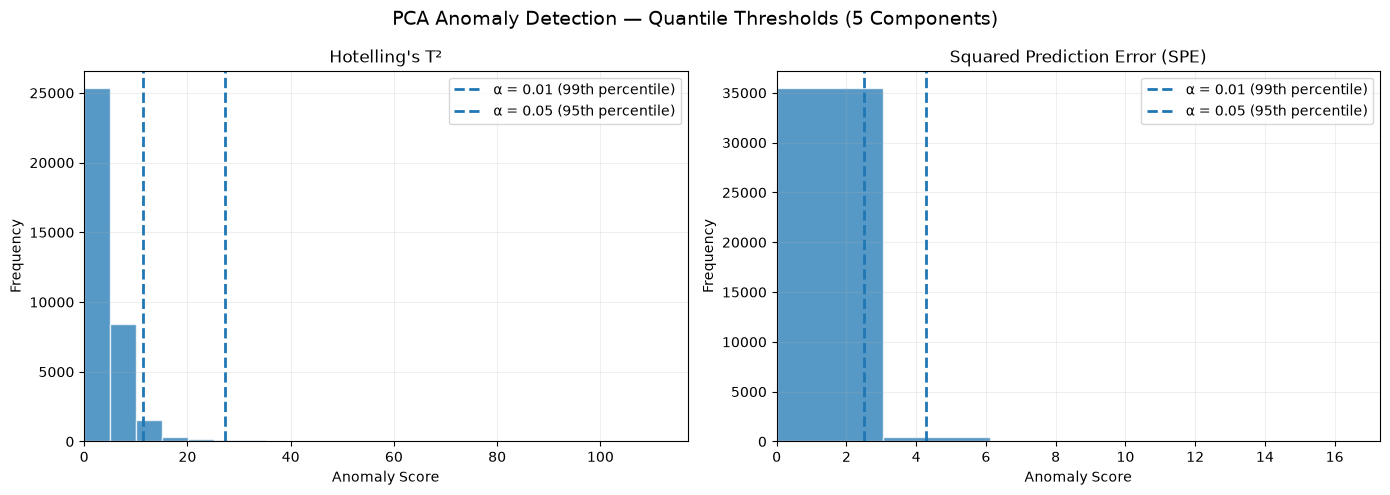

In [12]:
plot_pca_distributions(pca_detection)


### **3.4 $T^2$ Anomalies**

#### **3.4.1 Anomalies with $\alpha=0.05$**

Hotelling T² — Alpha = 0.05
Threshold: 11.4245
Anomalous observations: 1751
Non-anomalous observations: 34353
Anomaly rate: 4.85%

ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,1751.000,1751.000,1751.000,1751.000,1751.000,1751.000,1751.000,1751.000,1751.000,1751.00
mean,3.316,2.613,-185.100,343.135,47.347,0.120,-0.930,2.553,390.481,271.38
std,1.876,1.563,306.059,262.553,51.575,0.087,1.041,1.782,291.785,326.23
min,0.000,0.000,-2205.000,9.230,0.000,0.000,-2.750,1.000,11.540,9.99
25%,2.000,1.000,-351.730,193.990,9.040,0.030,-1.700,1.000,200.000,59.99
50%,3.000,4.000,-230.060,299.990,30.000,0.120,-0.830,1.000,399.960,129.99
75%,5.000,4.000,79.090,399.960,75.000,0.180,0.220,5.000,461.480,399.98
max,6.000,4.000,720.000,1679.990,500.000,0.250,0.500,5.000,1999.990,1999.99



NON-ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,34353.000,34353.000,34353.000,34353.000,34353.000,34353.000,34353.000,34353.000,34353.000,34353.000
mean,3.512,2.945,32.975,174.871,19.235,0.100,0.175,2.090,194.106,135.523
std,1.615,1.365,61.392,100.654,18.270,0.069,0.338,1.423,109.902,119.353
min,0.000,0.000,-302.380,8.290,0.000,0.000,-1.800,1.000,9.990,9.990
25%,2.000,2.000,9.070,100.780,5.200,0.040,0.080,1.000,119.980,50.000
50%,3.000,4.000,32.490,159.940,13.600,0.090,0.280,1.000,179.970,59.990
75%,5.000,4.000,64.800,239.980,28.000,0.160,0.360,3.000,260.650,199.990
max,6.000,4.000,237.800,527.250,100.000,0.250,0.500,5.000,532.580,532.580



HOTELLING T² SCORE COMPARISON


,Anomalous,Non-anomalous
count,1751.000,34353.000
mean,24.753,3.953
std,28.398,2.261
min,11.425,0.039
25%,12.617,2.260
50%,15.057,3.439
75%,22.852,5.201
max,301.929,11.424


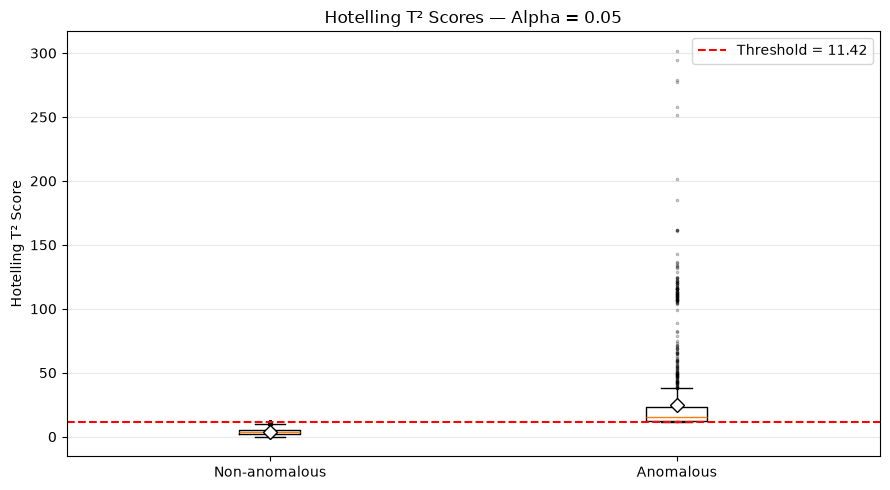

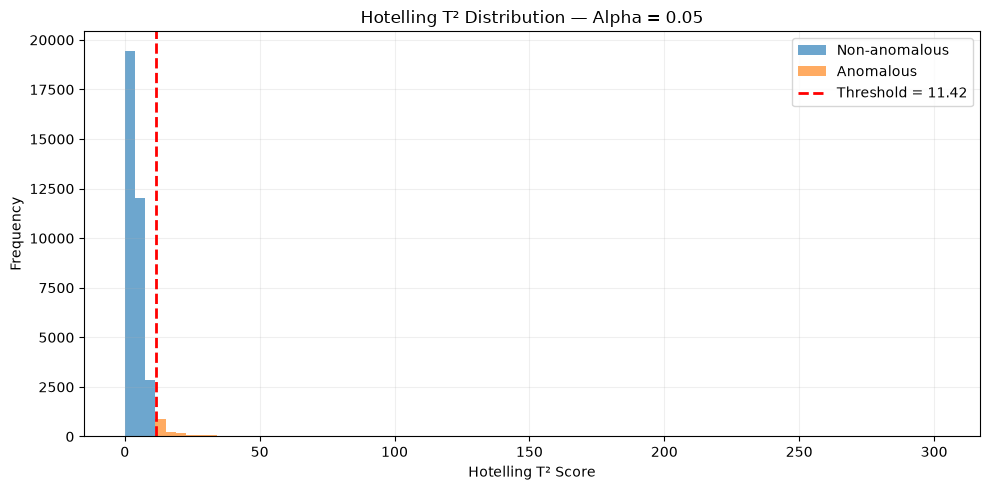

In [20]:
AnomalyAnalysis(pca_detection, "T2", alpha=0.05).present()


**Observations**

The Hotelling’s $T^2$ score measures how extreme each transaction is within the five-component PCA representation, accounting for the variance of each component. Using the training-score 95th percentile as the threshold ($T^2 > 11.424$), 1,751 validation transactions, approximately 4.85%, were flagged. These observations tend to exhibit lower profitability and higher transaction values than non-flagged observations. Higher scores indicate greater statistical extremeness within the retained PCA space, rather than a higher confirmed probability of fraud or data error.

The $T^2$-flagged transactions tend to involve larger monetary values and substantially lower profitability than non-flagged transactions. Higher product prices and absolute discounts also characterize the group. These patterns suggest extreme combinations of transaction value and profitability within the retained PCA space. Individual transactions may be flagged for different reasons; the descriptive statistics do not identify each observation’s exact score contributions or establish that it is erroneous.

#### **3.4.2 Anomalies with $\alpha=0.01$**

Hotelling T² — Alpha = 0.01
Threshold: 27.2927
Anomalous observations: 339
Non-anomalous observations: 35765
Anomaly rate: 0.94%

ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,339.000,339.000,339.000,339.000,339.000,339.000,339.000,339.000,339.000,339.000
mean,3.667,2.988,-412.327,580.453,65.873,0.097,-1.538,1.740,646.326,593.006
std,1.713,1.391,489.323,470.475,84.906,0.070,1.102,1.396,526.514,566.424
min,0.000,0.000,-2205.000,97.490,0.000,0.000,-2.750,1.000,119.990,31.990
25%,2.000,2.000,-666.370,284.230,12.000,0.030,-2.550,1.000,299.980,174.990
50%,4.000,4.000,-560.250,371.960,36.000,0.090,-1.700,1.000,399.980,399.980
75%,5.000,4.000,-357.545,1125.000,72.000,0.160,-1.055,1.000,1500.000,1500.000
max,6.000,4.000,720.000,1679.990,500.000,0.250,0.500,5.000,1999.990,1999.990



NON-ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,35765.000,35765.000,35765.000,35765.000,35765.000,35765.000,35765.000,35765.000,35765.000,35765.000
mean,3.501,2.928,26.519,179.265,20.169,0.101,0.137,2.116,199.434,137.838
std,1.629,1.377,79.674,104.020,19.996,0.071,0.426,1.445,114.319,121.543
min,0.000,0.000,-545.970,8.290,0.000,0.000,-2.750,1.000,9.990,9.990
25%,2.000,2.000,7.500,103.990,5.400,0.040,0.080,1.000,119.980,50.000
50%,3.000,4.000,31.680,163.930,14.000,0.090,0.270,1.000,199.920,59.990
75%,5.000,4.000,65.000,245.980,28.800,0.160,0.360,3.000,299.950,199.990
max,6.000,4.000,258.350,599.990,133.150,0.250,0.500,5.000,599.990,599.990



HOTELLING T² SCORE COMPARISON


,Anomalous,Non-anomalous
count,339.000,35765.000
mean,63.886,4.403
std,46.967,3.233
min,27.453,0.039
25%,31.704,2.309
50%,41.931,3.554
75%,106.211,5.543
max,301.929,27.281


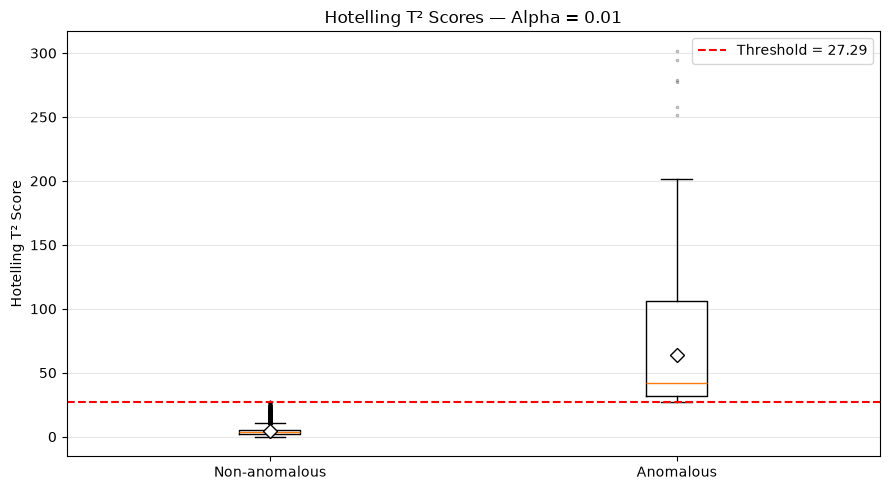

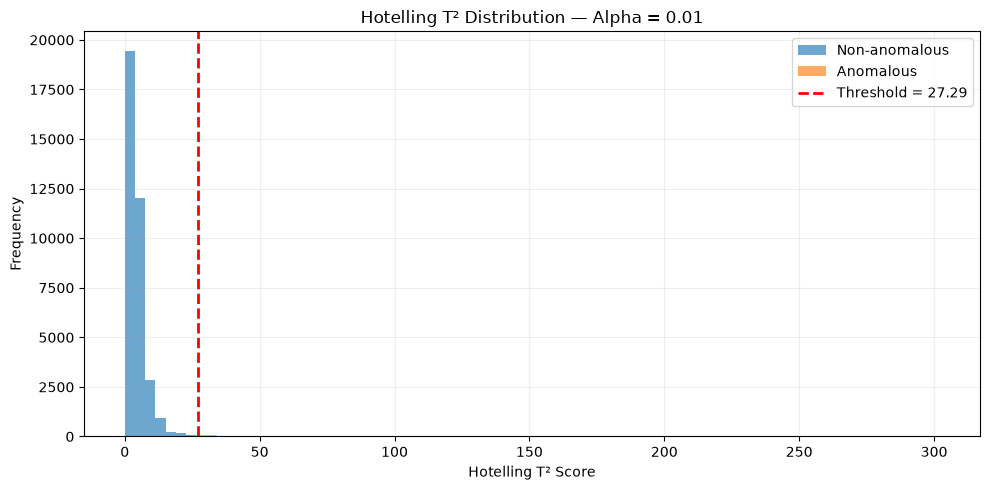

In [21]:
AnomalyAnalysis(pca_detection, "T2", alpha=0.01).present()


Using the 1% criterion increases the Hotelling’s $T^2$ threshold from 11.424 to 27.293, reducing the flagged validation observations from 1,751 (4.85%) to 339 (0.94%). These 339 observations are a subset of those identified under the 5% criterion. The PCA model and individual scores remain unchanged; the higher threshold simply selects more extreme transactions.

The selected group consequently has a higher mean $T^2$ score, increasing from 24.753 to 63.886, and a higher median, rising from 15.057 to 41.931. Its transactions exhibit more severe profitability deviations: median benefit per order decreases from −230.06 to −560.25, while the median profit ratio declines from −0.83 to −1.70. Median product price also increases from 129.99 to 399.98. Although median sales remains approximately 400, higher mean sales indicates greater influence from very large transactions.

Therefore, the 5% criterion captures a broader range of unusual transactions, whereas the 1% criterion concentrates on more extreme combinations of profitability and transaction value. These higher scores indicate greater statistical extremeness within the retained PCA space, without establishing fraud or data errors.

### **3.5 SPE**

#### **3.5.1 Anomalies with $\alpha=0.05$**

PCA SPE — Alpha = 0.05
Threshold: 2.4922
Anomalous observations: 1790
Non-anomalous observations: 34314
Anomaly rate: 4.96%

ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,1790.000,1790.000,1790.000,1790.000,1790.000,1790.000,1790.000,1790.000,1790.000,1790.000
mean,4.934,2.498,-62.250,240.324,28.466,0.107,-0.456,1.863,268.790,213.888
std,1.645,0.997,261.058,283.954,47.075,0.078,1.000,1.358,316.783,322.556
min,0.000,0.000,-2205.000,8.470,0.000,0.000,-2.750,1.000,11.290,9.990
25%,4.000,2.000,-104.575,73.698,4.800,0.040,-1.500,1.000,79.980,49.980
50%,6.000,2.000,9.550,127.970,12.000,0.090,0.090,1.000,149.940,99.990
75%,6.000,4.000,54.380,339.980,30.000,0.170,0.340,2.000,399.980,299.980
max,6.000,4.000,720.000,1679.990,500.000,0.250,0.500,5.000,1999.990,1999.990



NON-ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,34314.000,34314.000,34314.000,34314.000,34314.000,34314.000,34314.000,34314.000,34314.000,34314.000
mean,3.428,2.951,26.814,180.043,20.188,0.101,0.152,2.125,200.231,138.367
std,1.594,1.390,83.146,103.195,19.730,0.070,0.398,1.449,113.321,121.975
min,0.000,0.000,-801.850,8.290,0.000,0.000,-2.750,1.000,9.990,9.990
25%,2.000,2.000,8.200,106.210,5.400,0.040,0.080,1.000,119.980,50.000
50%,3.000,4.000,32.110,164.000,14.000,0.090,0.270,1.000,199.920,59.990
75%,5.000,4.000,65.240,245.980,29.990,0.160,0.360,3.000,299.950,199.990
max,6.000,4.000,330.000,1365.000,195.000,0.250,0.500,5.000,1500.000,1500.000



SPE SCORE COMPARISON


,Anomalous,Non-anomalous
count,1790.000,34314.000
mean,4.495,0.601
std,8.788,0.567
min,2.492,0.000
25%,2.568,0.157
50%,2.764,0.374
75%,3.811,0.810
max,183.503,2.492


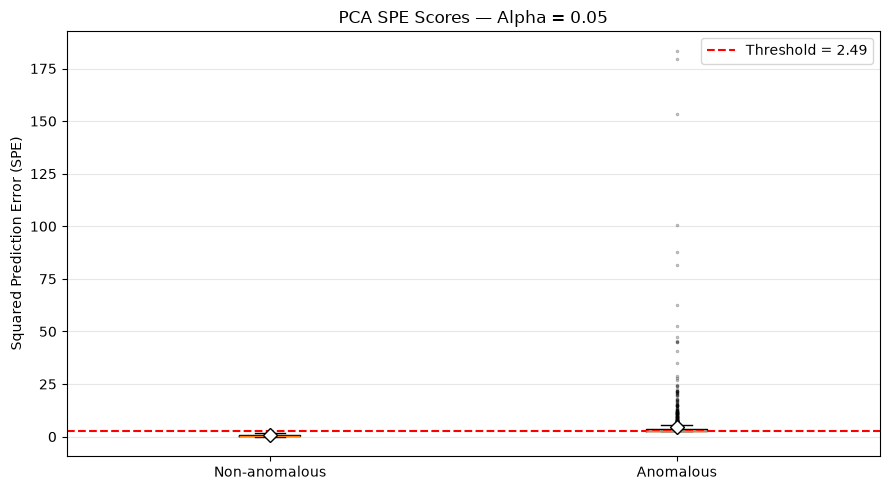

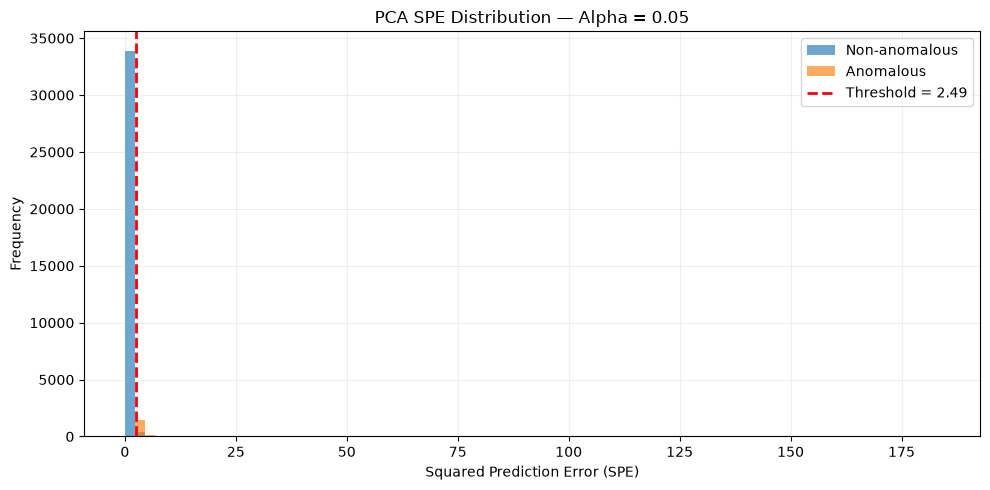

In [22]:
AnomalyAnalysis(pca_detection, "SPE", alpha=0.05).present()


Using the 5% criterion, SPE flags 1,790 validation observations (4.96%) whose scores exceed 2.4922. Their mean SPE is 4.495, compared with 0.601 for non-flagged observations, indicating substantially greater reconstruction error under the five-component PCA model. The anomalous median is 2.764, relatively close to the threshold, while the maximum reaches 183.503, showing that some observations have exceptionally large residuals.

Shipping duration provides the clearest descriptive distinction. Flagged observations have a mean actual-minus-scheduled shipping duration of approximately 2.44 days, compared with 0.48 days for non-flagged transactions. They also exhibit lower profitability: median benefit per order is 9.55 versus 32.11, and median profit ratio is 0.09 versus 0.27. Their negative mean benefit of −62.25 indicates that substantial losses affect part of the flagged group.

Transaction values are heterogeneous: mean sales is higher among flagged observations, but median sales is lower, suggesting that unusually large transactions influence the average. Overall, the flagged group exhibits more pronounced shipping discrepancies and weaker profitability.

#### **3.5.2 Anomalies with $\alpha=0.01$**

PCA SPE — Alpha = 0.01
Threshold: 4.2861
Anomalous observations: 362
Non-anomalous observations: 35742
Anomaly rate: 1.00%

ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,362.000,362.000,362.000,362.000,362.000,362.000,362.000,362.000,362.000,362.000
mean,3.688,3.086,-188.590,420.782,48.256,0.106,-1.490,1.467,469.037,436.061
std,1.692,1.283,447.830,519.838,85.014,0.075,1.033,1.058,579.727,591.795
min,0.000,0.000,-2205.000,9.230,0.000,0.000,-2.750,1.000,11.290,9.990
25%,2.000,2.000,-306.663,46.682,4.000,0.040,-2.500,1.000,50.000,49.980
50%,4.000,4.000,-91.120,103.990,11.250,0.100,-1.650,1.000,119.990,79.990
75%,5.000,4.000,-41.378,451.428,45.000,0.168,-1.500,1.000,499.950,452.040
max,6.000,4.000,720.000,1679.990,500.000,0.250,0.500,5.000,1999.990,1999.990



NON-ANOMALOUS OBSERVATIONS — ORIGINAL FEATURES


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
count,35742.000,35742.000,35742.000,35742.000,35742.000,35742.000,35742.000,35742.000,35742.000,35742.000
mean,3.501,2.927,24.535,180.624,20.318,0.101,0.138,2.119,200.942,139.134
std,1.629,1.377,89.134,105.474,20.176,0.070,0.427,1.447,116.018,123.861
min,0.000,0.000,-831.960,8.290,0.000,0.000,-2.750,1.000,9.990,9.990
25%,2.000,2.000,7.560,104.380,5.400,0.040,0.080,1.000,119.980,50.000
50%,3.000,4.000,31.690,163.990,14.000,0.090,0.270,1.000,199.920,65.000
75%,5.000,4.000,65.070,247.400,29.990,0.160,0.360,3.000,299.950,199.990
max,6.000,4.000,456.300,1365.000,195.000,0.250,0.500,5.000,1500.000,1500.000



SPE SCORE COMPARISON


,Anomalous,Non-anomalous
count,362.000,35742.000
mean,11.021,0.691
std,18.124,0.713
min,4.296,0.000
25%,5.080,0.163
50%,6.281,0.408
75%,10.552,0.991
max,183.503,4.285


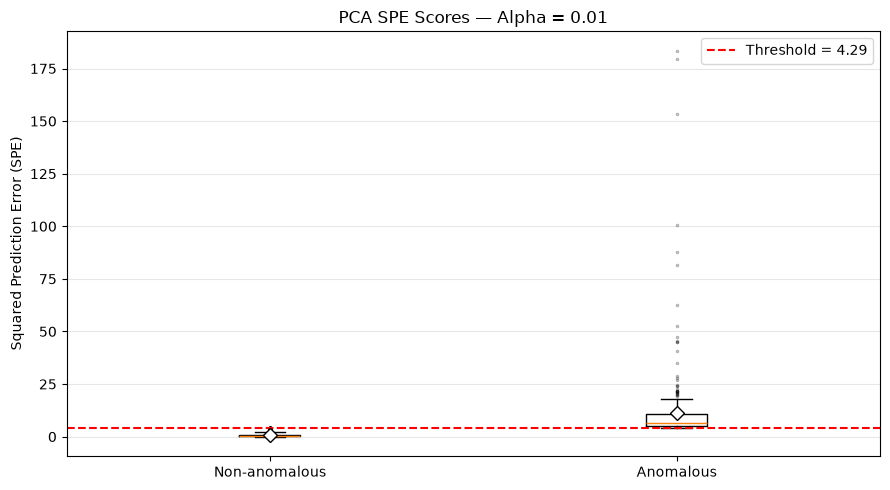

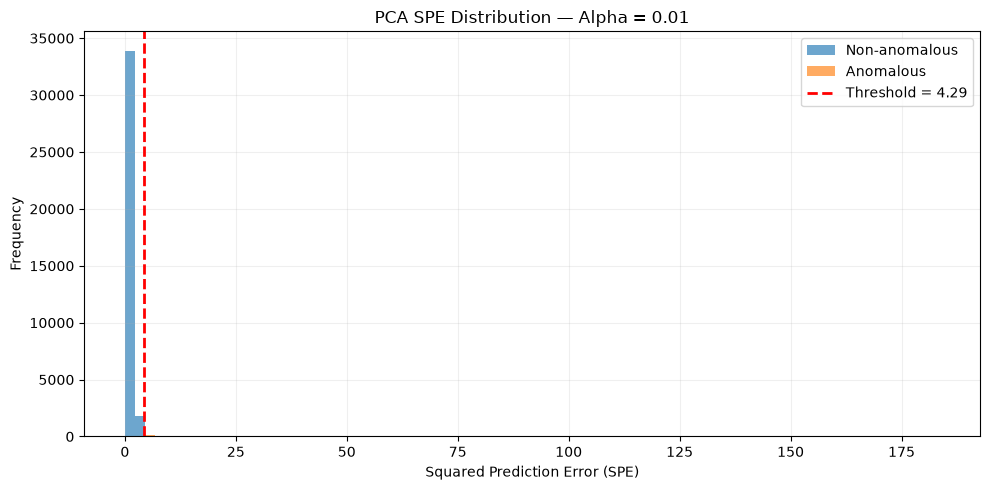

In [23]:
AnomalyAnalysis(pca_detection, "SPE", alpha=0.01).present()


**Observations**

The 1% criterion selects transactions with larger reconstruction errors. Its 362 flagged observations are a subset of the 1,790 flagged at 5%; raising the threshold removes 1,428 less extreme observations. The model and individual SPE scores do not change. The higher mean and median scores follow from selecting a more extreme tail, rather than from improving the model.

The main descriptive difference is a shift from prominent shipping discrepancies toward more pronounced profitability deviations. At 5%, flagged transactions average approximately 2.44 additional shipping days relative to schedule; this falls to 0.60 days at 1%. Meanwhile, median benefit becomes negative and the median profit ratio falls sharply. The 1% group’s 75th-percentile benefit is also negative (−41.38), indicating that roughly three-quarters of its transactions have negative benefits.

The 1% group remains heterogeneous: mean sales increases while median sales decreases, showing that some very large transactions pull the average upward. These results suggest that the most severe reconstruction failures are associated with unusual financial combinations, although individual feature residuals are needed to establish the exact reason for each flag. A high SPE measures poor fit to the retained PCA relationships; it does not confirm fraud or incorrect data.

## **4. Independent Component Analysis (ICA)**

### **4.1 Negative Log-Likelihood (NLL) and Squared Prediction Error (SPE)**

**Negative Log-Likelihood (NLL)** and **Squared Prediction Error (SPE)** are anomaly scores used in Independent Component Analysis (ICA) to identify statistically unusual observations.

Both measure different deviations from the ICA model: NLL evaluates how unusual an observation is within the retained independent-component representation, while SPE measures how accurately the observation can be reconstructed.

| Statistic | What it measures | Type of anomaly |
|---|---|---|
| **Negative Log-Likelihood (NLL)** | How unlikely an observation's independent-component scores are under their estimated densities | Low-density anomaly within the retained ICA representation |
| **Squared Prediction Error (SPE)** | How much of an observation cannot be reconstructed using the retained components | Anomaly outside the retained ICA subspace |

**1. Negative Log-Likelihood (NLL)**

ICA transforms the original numerical variables into components that are approximately statistically independent.

Assuming independence, the joint density of an observation can be estimated by multiplying the individual component densities. The NLL anomaly score is calculated as:

$$
\boxed{NLL_i=-\sum_{j=1}^{k}\log\hat p_j(s_{ij})}
$$

Where:

- $NLL_i$: Anomaly score for observation $i$.
- $k$: Number of retained independent components (5 in our experiment).
- $s_{ij}$: Score of observation $i$ on independent component $j$.
- $\hat p_j(s_{ij})$: Estimated probability density of that score.
- $\log$: Natural logarithm.

The component densities will be estimated using **Kernel Density Estimation (KDE)**, which does not require assuming normally distributed components.

A **higher NLL indicates that an observation is located in a region of relatively low estimated density**, making it potentially anomalous.

Unlike a probability of anomaly, NLL is a density-based score whose interpretation depends on the estimated component distributions.

**2. Squared Prediction Error (SPE)**

SPE measures the reconstruction error between an original standardized observation and its reconstruction using the retained ICA components.

The statistic is calculated as:

$$
\boxed{SPE_i=\|\mathbf{x}_i-\hat{\mathbf{x}}_i\|^2}
$$

Equivalently:

$$
SPE_i=\sum_{j=1}^{D}(x_{ij}-\hat{x}_{ij})^2
$$

Where:

- $SPE_i$: Reconstruction-error anomaly score for observation $i$.
- $\mathbf{x}_i$: Original standardized observation.
- $\hat{\mathbf{x}}_i$: Observation reconstructed using ICA.
- $D$: Number of original numerical features (10 in our experiment).
- $x_{ij}$ and $\hat{x}_{ij}$: Original and reconstructed values of feature $j$.

A **higher SPE indicates that an observation deviates more strongly from the retained ICA subspace**.

However, ICA seeks statistically independent components rather than minimizing reconstruction error.

Additionally, scikit-learn's `FastICA` performs PCA-based dimensionality reduction before estimating independent components. Therefore, when PCA and ICA retain the same five components, their SPE scores may be nearly identical.

For this reason, **NLL will be our primary ICA-specific anomaly score**, while SPE will serve as a secondary measure for comparison with PCA.

**3. Threshold Selection Using Upper-Tail Proportions**

Both statistics produce numerical anomaly scores that must be compared against thresholds to classify observations as potentially anomalous.

We will use the same empirical quantile approach applied in PCA, evaluating two upper-tail proportions:

- **$\alpha=0.01$ (1%):** The 99th percentile of training scores, identifying the most extreme observations.
- **$\alpha=0.05$ (5%):** The 95th percentile of training scores, identifying a broader group of potentially anomalous observations.

The threshold is calculated as:

$$
\boxed{\tau_{\alpha}=Q_{1-\alpha}(S_{\text{train}})}
$$

Where:

- $\tau_{\alpha}$: Anomaly-detection threshold.
- $Q_{1-\alpha}$: Empirical quantile at probability $1-\alpha$.
- $S_{\text{train}}$: Training anomaly-score distribution.

An observation is classified as anomalous when:

$$
\text{Anomaly}_{\alpha}(x_i)=
\begin{cases}
1 & \text{if }s_i>\tau_{\alpha}\\
0 & \text{if }s_i\leq\tau_{\alpha}
\end{cases}
$$

Thresholds will be calculated **independently for NLL and SPE using training observations** and subsequently applied to validation and test data.

The selected proportions are not verified anomaly prevalence. Although approximately 1% and 5% of training observations will exceed the corresponding thresholds, the detected proportions in validation and test may differ.

**4. Interpretation and Limitations**

NLL and SPE provide complementary perspectives of ICA-based anomaly detection.

An observation may have a **high NLL but low SPE**, indicating unusual independent-component scores despite being reconstructed accurately. Conversely, an observation may have a **low NLL but high SPE**, indicating common retained component scores but substantial reconstruction error.

**False Positives and False Negatives**

The threshold influences the trade-off between potential false positives and false negatives.

With **$\alpha=0.01$**, the stricter criterion flags fewer observations, potentially reducing false positives but increasing the risk of missing unusual transactions.

With **$\alpha=0.05$**, the less restrictive criterion flags more observations, potentially reducing false negatives while increasing false positives.

However, **actual false-positive and false-negative rates cannot be calculated without verified anomaly labels**. Instead, we will analyze the numerical characteristics of flagged and non-flagged transactions.

**Stability and Agreement**

ICA stability can be evaluated by comparing anomaly detections across different training samples, random seeds, or KDE bandwidths while maintaining the same upper-tail proportions.

Agreement between NLL and SPE can be measured using the **Jaccard similarity coefficient**:

$$
\boxed{J(A,B)=\frac{|A\cap B|}{|A\cup B|}}
$$

Where $A$ and $B$ represent the sets of observations flagged by NLL and SPE, respectively.

A higher Jaccard coefficient indicates greater agreement, although this does not necessarily imply better detection performance.

Finally, comparing ICA-based NLL with PCA-based Hotelling's $T^2$ will help determine whether density-based analysis identifies unusual observations that are not captured by variance-normalized PCA scores.

**Consequently, our objective is to identify statistically unusual transactions, characterize their numerical properties, and evaluate how anomaly detection varies across statistics, thresholds, and model configurations, rather than confirming fraudulent or erroneous transactions.**

### **4.2 Running ICA with 5 Components**

In [24]:
ica_detection = ICAAnomalyDetector(n_components=5, bandwidth=0.3, kde_sample_size=5000).fit(data)
ica_detection.display()


ICA components: 5
Iterations: 5
Converged: True
ICA fitting time: 0.16 seconds
KDE training observations: 5000
KDE fitting time: 0.04 seconds
ICA scoring time: 184.11 seconds

TRAINING SCORE SUMMARY


,NLL,SPE
count,108311.0000,108311.0000
mean,5.7059,0.8079
std,4.9593,3.0182
min,3.0949,0.0002
25%,4.6060,0.1644
50%,5.3383,0.4149
75%,6.3373,1.0626
max,968.5299,420.1850



ICA QUANTILE THRESHOLDS


,Alpha,Percentile,NLL Threshold,SPE Threshold,NLL Training Anomaly Rate (%),SPE Training Anomaly Rate (%)
0,0.01,99.0,11.0141,4.2861,1.0008,1.0008
1,0.05,95.0,8.8290,2.4922,5.0004,5.0004



ICA ANOMALY DETECTION COMPARISON


,Dataset,Alpha,NLL Anomalies,SPE Anomalies,NLL Only,SPE Only,Both,Either,NLL Anomaly Rate (%),SPE Anomaly Rate (%),Either Anomaly Rate (%),Jaccard
0,Training,0.01,1084,1084,593,593,491,1677,1.0008,1.0008,1.5483,0.2928
1,Training,0.05,5416,5416,3777,3777,1639,9193,5.0004,5.0004,8.4876,0.1783
2,Validation,0.01,348,362,204,218,144,566,0.9639,1.0027,1.5677,0.2544
3,Validation,0.05,1791,1790,1254,1253,537,3044,4.9607,4.9579,8.4312,0.1764
4,Test,0.01,328,347,182,201,146,529,0.9085,0.9611,1.4652,0.2760
5,Test,0.05,1771,1750,1249,1228,522,2999,4.9053,4.8471,8.3066,0.1741



Results saved successfully.


,ICA_NLL,ICA_SPE,NLL_Anomaly_Alpha_0_01,SPE_Anomaly_Alpha_0_01,Either_Anomaly_Alpha_0_01,Both_Anomaly_Alpha_0_01,NLL_Anomaly_Alpha_0_05,SPE_Anomaly_Alpha_0_05,Either_Anomaly_Alpha_0_05,Both_Anomaly_Alpha_0_05
105330,5.767752,0.037851,False,False,False,False,False,False,False,False
111731,8.194765,1.299539,False,False,False,False,False,False,False,False
26280,7.446908,0.293522,False,False,False,False,False,False,False,False
2124,6.016321,1.492660,False,False,False,False,False,False,False,False
34886,4.718993,0.600027,False,False,False,False,False,False,False,False


### **4.3 Negative Log-Likelihood (NLL)**

#### **4.3.1 Anomalies with $\alpha=0.05$**

ICA NLL | 95TH PERCENTILE | VALIDATION
Threshold: 8.8290
Total observations: 36,104
Anomalous: 1,791
Non-anomalous: 34,313
Anomaly rate: 4.96%

NLL - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1791.0    3.2161    1.8402   
              Days for shipment (scheduled)   1791.0    2.5310    1.5564   
              Benefit per order               1791.0 -187.0598  289.1867   
              Sales per customer              1791.0  334.3190  265.4425   
              Order Item Discount             1791.0   43.6650   50.3033   
              Order Item Discount Rate        1791.0    0.1178    0.0862   
              Order Item Profit Ratio         1791.0   -0.9352    0.9579   
              Order Item Quantity             1791.0    2.7426    1.7172   
              Sales                           1791.0  377.9832  294.1378   
              Product Price                   1791.0  250.6783  329.8457   
Non-Anomalous Days for shipping (real)       34313.0    3.5174    1.6165   
              Days for shipment (scheduled)  34313.0    2.9494    1.3635   
              Benefit per order              34313.0   33.3312   63.9357   
              Sales per customer             34313.0  175.1354  100.5032   
              Order Item Discount            34313.0   19.3940   18.6275   
              Order Item Discount Rate       34313.0    0.1005    0.0695   
              Order Item Profit Ratio        34313.0    0.1766    0.3457   
              Order Item Quantity            34313.0    2.0792    1.4222   
              Sales                          34313.0  194.5292  110.1106   
              Product Price                  34313.0  136.4448  119.4268   

                                                 min      25%     50%  \
Group         Feature                                                   
Anomalous     Days for shipping (real)          0.00    2.000    3.00   
              Days for shipment (scheduled)     0.00    1.000    2.00   
              Benefit per order             -2205.00 -335.980 -177.01   
              Sales per customer                9.23  188.995  299.97   
              Order Item Discount               0.00    8.000   28.00   
              Order Item Discount Rate          0.00    0.030    0.12   
              Order Item Profit Ratio          -2.75   -1.650   -0.80   
              Order Item Quantity               1.00    1.000    2.00   
              Sales                            11.29  200.000  325.00   
              Product Price                     9.99   59.990   99.99   
Non-Anomalous Days for shipping (real)          0.00    2.000    3.00   
              Days for shipment (scheduled)     0.00    2.000    4.00   
              Benefit per order              -527.97    9.580   33.00   
              Sales per customer                8.29  101.980  159.96   
              Order Item Discount               0.00    5.200   13.74   
              Order Item Discount Rate          0.00    0.040    0.09   
              Order Item Profit Ratio          -2.75    0.090    0.28   
              Order Item Quantity               1.00    1.000    1.00   
              Sales                             9.99  119.980  179.97   
              Product Price                     9.99   50.000   59.99   

                                                 75%      max  
Group         Feature                                          
Anomalous     Days for shipping (real)         5.000     6.00  
              Days for shipment (scheduled)    4.000     4.00  
              Benefit per order              -19.305   720.00  
              Sales per customer             399.440  1679.99  
              Order Item Discount             68.000   500.00  
              Order Item Discount Rate         0.180     0.25  
              Order Item Profit Ratio         -0.060     0.50  
              Order Item Quantity              5.000     5.00  
              Sales                          452.040  1999.99  
              Product Price                  399.980  1999.99  


NLL - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1791.0000,34313.0000
mean,10.8526,5.4148
std,9.0593,1.2424
min,8.8299,3.0949
25%,9.2368,4.5470
50%,9.8137,5.2611
75%,10.7128,6.1132
max,236.0974,8.8290


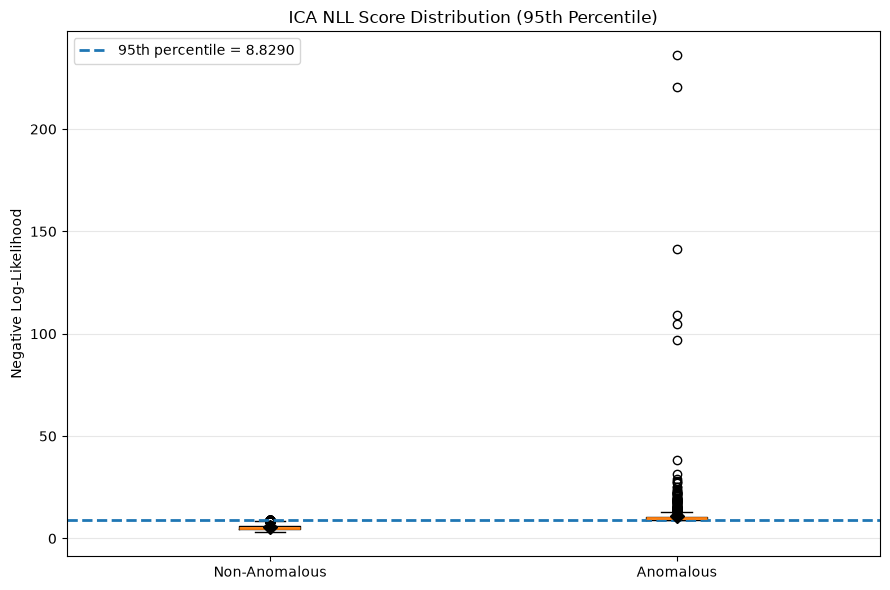

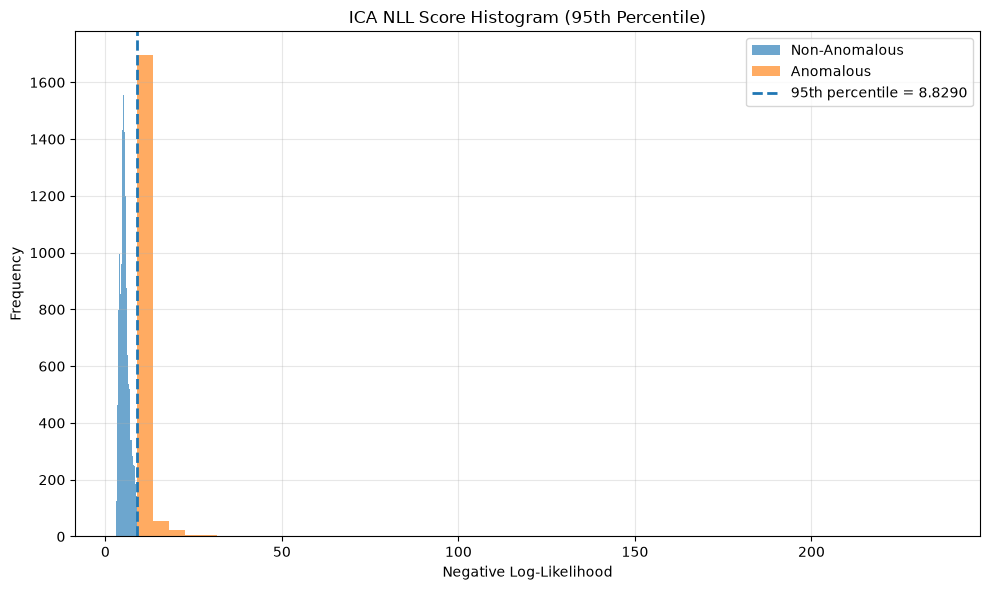


ICA NLL descriptive analysis completed successfully.


In [27]:
AnomalyAnalysis(ica_detection, "NLL", alpha=0.05).present()


**Observations**

Using the 5% criterion, ICA’s Negative Log-Likelihood (NLL) flags 1,791 validation observations (4.96%) whose scores exceed the training-derived threshold of 8.829. Their mean NLL is 10.853, compared with 5.415 for non-flagged observations, while their median is 9.814 versus 5.261. Higher NLL values indicate that the independent-component scores lie in regions of lower estimated density, making these transactions less typical of the training distribution. The maximum NLL of 236.097 identifies an exceptionally low-density observation, although this score is not a probability of fraud or error.

The main pattern among flagged transactions is lower profitability combined with higher transaction values. Median benefit per order is −177.01, compared with 33.00 for non-flagged transactions, and median profit ratio is −0.80 versus 0.28. Approximately three-quarters of flagged observations have negative benefits, as their 75th percentile is −19.31. Median sales increases from 179.97 to 325.00, accompanied by higher product prices, absolute discounts, and purchased quantities.

#### **4.3.2 Anomalies with $\alpha=0.01$**

ICA NLL | 99TH PERCENTILE | VALIDATION
Threshold: 11.0141
Total observations: 36,104
Anomalous: 348
Non-anomalous: 35,756
Anomaly rate: 0.96%

NLL - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         348.0    3.2557    1.8598   
              Days for shipment (scheduled)    348.0    2.6121    1.5767   
              Benefit per order                348.0 -243.1693  483.8431   
              Sales per customer               348.0  580.2866  441.7471   
              Order Item Discount              348.0   79.5824   81.6842   
              Order Item Discount Rate         348.0    0.1299    0.0923   
              Order Item Profit Ratio          348.0   -0.9198    1.1296   
              Order Item Quantity              348.0    2.4943    1.8101   
              Sales                            348.0  659.8680  484.8264   
              Product Price                    348.0  531.2225  566.3572   
Non-Anomalous Days for shipping (real)       35756.0    3.5049    1.6270   
              Days for shipment (scheduled)  35756.0    2.9317    1.3742   
              Benefit per order              35756.0   24.9830   86.3526   
              Sales per customer             35756.0  179.1657  104.7962   
              Order Item Discount            35756.0   20.0239   19.7169   
              Order Item Discount Rate       35756.0    0.1010    0.0702   
              Order Item Profit Ratio        35756.0    0.1316    0.4432   
              Order Item Quantity            35756.0    2.1083    1.4410   
              Sales                          35756.0  199.1894  115.0724   
              Product Price                  35756.0  138.3245  123.1023   

                                                 min       25%      50%  \
Group         Feature                                                     
Anomalous     Days for shipping (real)          0.00    2.0000    3.000   
              Days for shipment (scheduled)     0.00    1.0000    4.000   
              Benefit per order             -2205.00 -587.9100 -234.605   
              Sales per customer                9.23  299.9900  395.980   
              Order Item Discount               0.00   17.4925   64.000   
              Order Item Discount Rate          0.00    0.0300    0.130   
              Order Item Profit Ratio          -2.75   -1.7500   -0.745   
              Order Item Quantity               1.00    1.0000    1.000   
              Sales                            11.54  399.9600  499.950   
              Product Price                    11.54   99.9900  399.980   
Non-Anomalous Days for shipping (real)          0.00    2.0000    3.000   
              Days for shipment (scheduled)     0.00    2.0000    4.000   
              Benefit per order              -800.20    7.4200   31.590   
              Sales per customer                8.29  103.9900  163.930   
              Order Item Discount               0.00    5.4000   14.000   
              Order Item Discount Rate          0.00    0.0400    0.090   
              Order Item Profit Ratio          -2.75    0.0800    0.270   
              Order Item Quantity               1.00    1.0000    1.000   
              Sales                             9.99  119.9800  199.920   
              Product Price                     9.99   50.0000   59.990   

                                                  75%      max  
Group         Feature                                           
Anomalous     Days for shipping (real)         5.0000     6.00  
              Days for shipment (scheduled)    4.0000     4.00  
              Benefit per order               99.6950   720.00  
              Sales per customer             528.5825  1679.99  
              Order Item Discount            100.5000   500.00  
              Order Item Discount Rate         0.2000     0.25  
              Order Item Profit Ratio          0.1650     0.50  
              Order Item Quantity              5.0000     5.00  
              Sales                          532.5800  1999.99  
        


NLL - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,348.0000,35756.0000
mean,15.7538,5.5866
std,19.7967,1.4825
min,11.0172,3.0949
25%,11.3458,4.5884
50%,12.1044,5.3153
75%,13.6245,6.2995
max,236.0974,11.0120


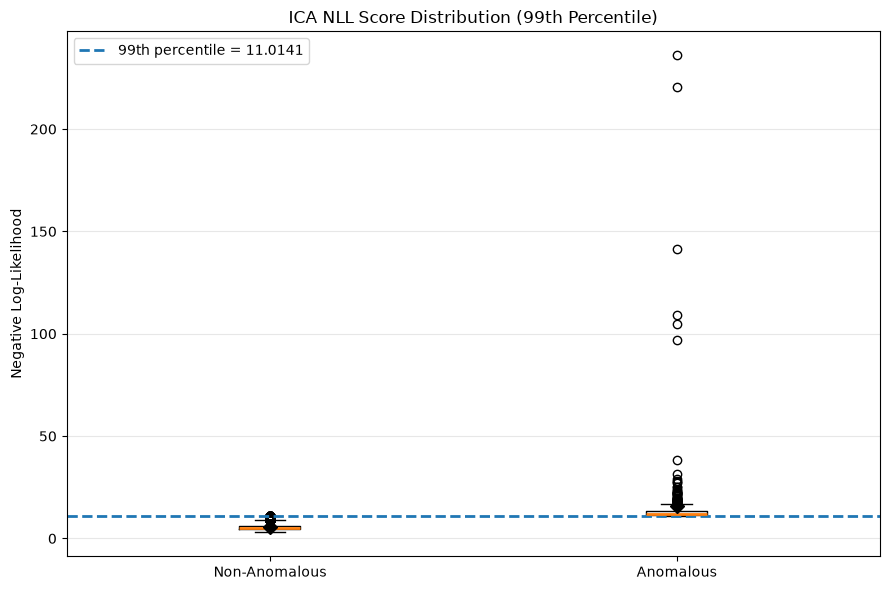

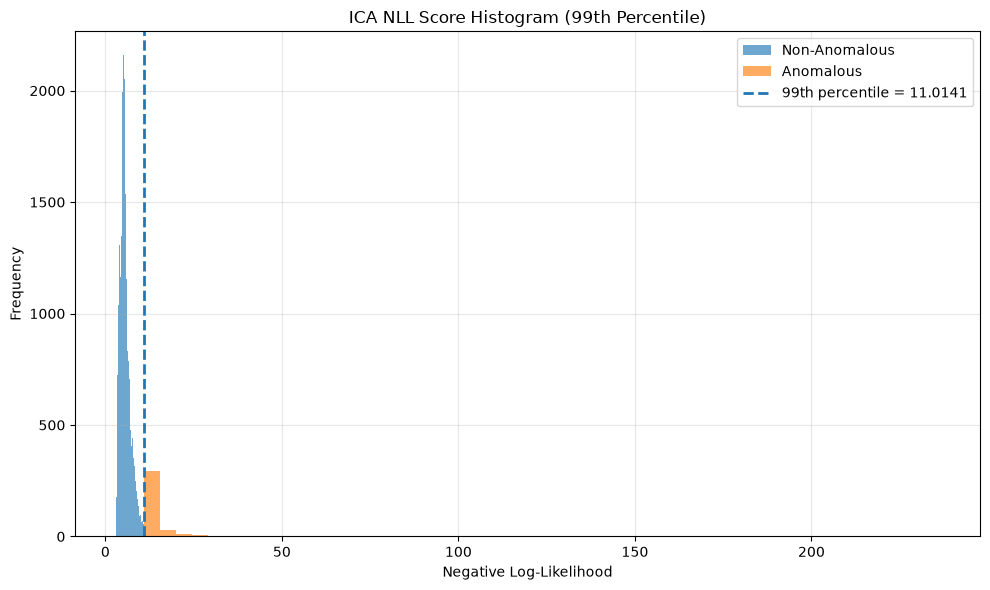


ICA NLL descriptive analysis completed successfully.


In [28]:
AnomalyAnalysis(ica_detection, "NLL", alpha=0.01).present()


**Observations**

Using the 1% criterion, ICA NLL flags 348 validation observations (0.96%) above the training-derived threshold of 11.014, compared with 1,791 observations under the 5% criterion. Their mean NLL is 15.754 and their median is 12.104, exceeding the corresponding values of 10.853 and 9.814 for the 5% anomalous group. This reflects the selection of a lower-density tail of the estimated ICA representation; the model and individual scores remain unchanged.

Compared with the 5% anomalous group, these transactions have higher median sales (499.95 versus 325.00), product prices (399.98 versus 99.99), and absolute discounts (64.00 versus 28.00). Median benefit becomes more negative, decreasing from −177.01 to −234.61. However, the median profit ratio is slightly less negative, showing that greater statistical rarity does not require every individual feature to become more extreme.

Overall, the 1% criterion concentrates on uncommon financial and purchasing profiles involving larger transaction amounts and substantial losses among many observations. Nevertheless, its positive upper-quartile benefit indicates that profitable transactions are also represented. Component-level NLL contributions are needed to explain individual flags, since the descriptive statistics characterize the group rather than establish the reason for every detection.

### **4.4 Squared Prediction Error (SPE)**

#### **4.4.1 Anomalies with $\alpha=0.05$**

ICA SPE | 95TH PERCENTILE | VALIDATION
Threshold: 2.4922
Total observations: 36,104
Anomalous: 1,790
Non-anomalous: 34,314
Anomaly rate: 4.96%

SPE - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1790.0    4.9335    1.6453   
              Days for shipment (scheduled)   1790.0    2.4978    0.9968   
              Benefit per order               1790.0  -62.2499  261.0585   
              Sales per customer              1790.0  240.3241  283.9537   
              Order Item Discount             1790.0   28.4658   47.0747   
              Order Item Discount Rate        1790.0    0.1068    0.0778   
              Order Item Profit Ratio         1790.0   -0.4562    0.9998   
              Order Item Quantity             1790.0    1.8626    1.3578   
              Sales                           1790.0  268.7895  316.7834   
              Product Price                   1790.0  213.8881  322.5559   
Non-Anomalous Days for shipping (real)       34314.0    3.4278    1.5939   
              Days for shipment (scheduled)  34314.0    2.9511    1.3900   
              Benefit per order              34314.0   26.8140   83.1460   
              Sales per customer             34314.0  180.0433  103.1952   
              Order Item Discount            34314.0   20.1876   19.7298   
              Order Item Discount Rate       34314.0    0.1010    0.0701   
              Order Item Profit Ratio        34314.0    0.1516    0.3978   
              Order Item Quantity            34314.0    2.1251    1.4487   
              Sales                          34314.0  200.2307  113.3212   
              Product Price                  34314.0  138.3673  121.9755   

                                                 min       25%     50%  \
Group         Feature                                                    
Anomalous     Days for shipping (real)          0.00    4.0000    6.00   
              Days for shipment (scheduled)     0.00    2.0000    2.00   
              Benefit per order             -2205.00 -104.5750    9.55   
              Sales per customer                8.47   73.6975  127.97   
              Order Item Discount               0.00    4.8000   12.00   
              Order Item Discount Rate          0.00    0.0400    0.09   
              Order Item Profit Ratio          -2.75   -1.5000    0.09   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                            11.29   79.9800  149.94   
              Product Price                     9.99   49.9800   99.99   
Non-Anomalous Days for shipping (real)          0.00    2.0000    3.00   
              Days for shipment (scheduled)     0.00    2.0000    4.00   
              Benefit per order              -801.85    8.2000   32.11   
              Sales per customer                8.29  106.2100  164.00   
              Order Item Discount               0.00    5.4000   14.00   
              Order Item Discount Rate          0.00    0.0400    0.09   
              Order Item Profit Ratio          -2.75    0.0800    0.27   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                             9.99  119.9800  199.92   
              Product Price                     9.99   50.0000   59.99   

                                                75%      max  
Group         Feature                                         
Anomalous     Days for shipping (real)         6.00     6.00  
              Days for shipment (scheduled)    4.00     4.00  
              Benefit per order               54.38   720.00  
              Sales per customer             339.98  1679.99  
              Order Item Discount             30.00   500.00  
              Order Item Discount Rate         0.17     0.25  
              Order Item Profit Ratio          0.34     0.50  
              Order Item Quantity              2.00     5.00  
              Sales                          399.98  1999.99  
              Product Price                  299.98 


SPE - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1790.0000,34314.0000
mean,4.4948,0.6012
std,8.7883,0.5672
min,2.4923,0.0002
25%,2.5679,0.1567
50%,2.7641,0.3743
75%,3.8105,0.8100
max,183.5032,2.4921


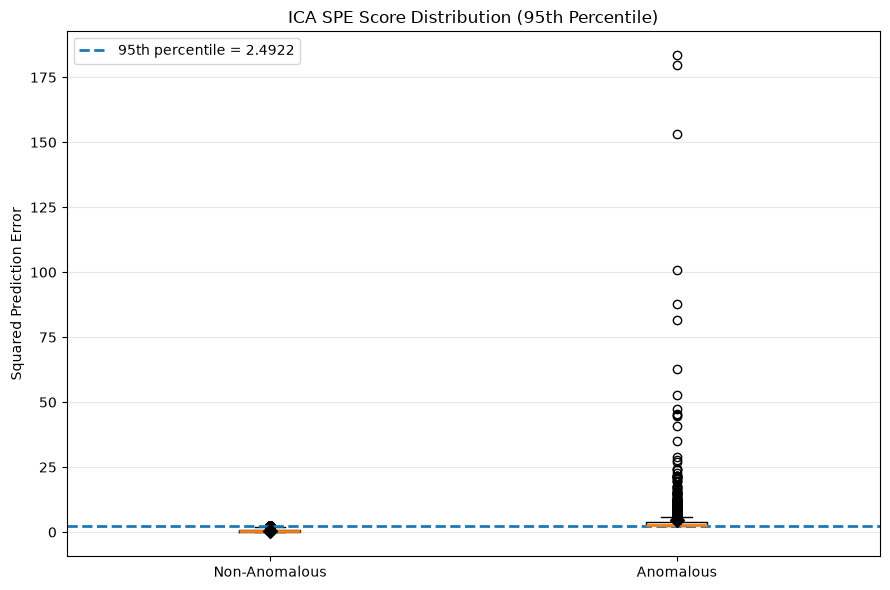

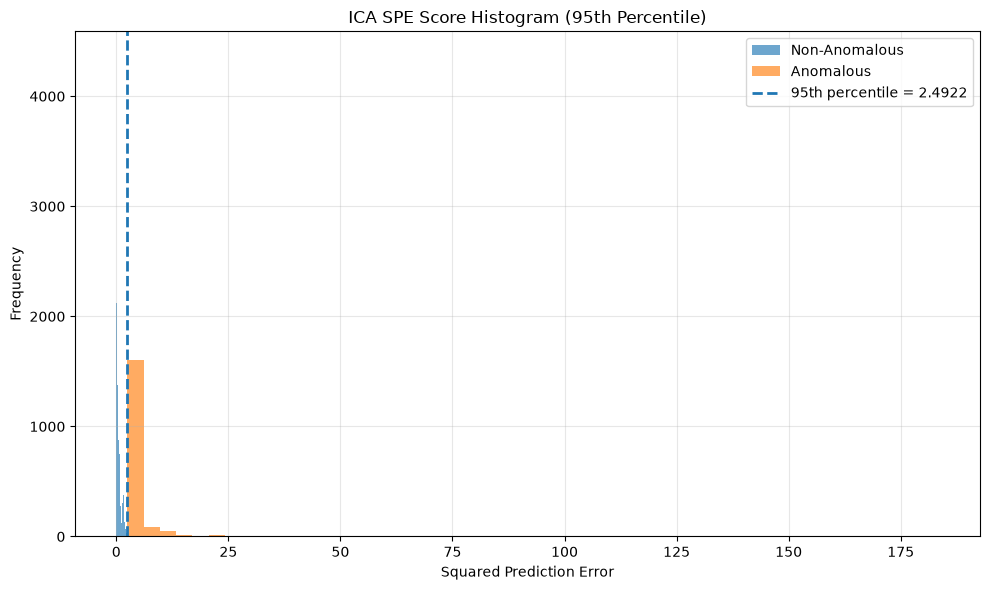


ICA SPE descriptive analysis completed successfully.


In [29]:
AnomalyAnalysis(ica_detection, "SPE", alpha=0.05).present()


**Observations**

Using the 5% criterion, ICA SPE flags 1,790 validation observations (4.96%) above the training-derived threshold of 2.4922. Their mean SPE is 4.495, compared with 0.601 for non-flagged observations, while their median is 2.764 versus 0.374. These scores indicate greater reconstruction error under the five-component ICA model. The maximum of 183.503 reveals that some transactions deviate substantially more strongly than the majority of flagged observations.

Shipping discrepancies provide the clearest descriptive distinction. Flagged transactions have a mean actual-minus-scheduled shipping duration of approximately 2.44 days, compared with 0.48 days for non-flagged transactions. Profitability is also lower: median benefit per order is 9.55 versus 32.11, and median profit ratio is 0.09 versus 0.27. Higher mean sales alongside lower median sales indicates a heterogeneous group containing some unusually large transactions.

Overall, ICA SPE identifies transactions whose feature combinations are poorly represented by the retained reconstruction space, particularly observations exhibiting shipping discrepancies and weaker profitability. The results match the PCA SPE findings to the displayed precision, consistent with both methods reconstructing through the same retained subspace. Individual feature residuals are needed to determine each transaction’s principal score contributions; a high SPE does not itself establish fraud or incorrect data.

#### **4.4.2 Anomalies with $\alpha=0.01$**

ICA SPE | 99TH PERCENTILE | VALIDATION
Threshold: 4.2861
Total observations: 36,104
Anomalous: 362
Non-anomalous: 35,742
Anomaly rate: 1.00%

SPE - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         362.0    3.6878    1.6922   
              Days for shipment (scheduled)    362.0    3.0856    1.2831   
              Benefit per order                362.0 -188.5899  447.8301   
              Sales per customer               362.0  420.7815  519.8381   
              Order Item Discount              362.0   48.2559   85.0144   
              Order Item Discount Rate         362.0    0.1056    0.0751   
              Order Item Profit Ratio          362.0   -1.4899    1.0328   
              Order Item Quantity              362.0    1.4669    1.0580   
              Sales                            362.0  469.0371  579.7271   
              Product Price                    362.0  436.0609  591.7948   
Non-Anomalous Days for shipping (real)       35742.0    3.5006    1.6289   
              Days for shipment (scheduled)  35742.0    2.9270    1.3775   
              Benefit per order              35742.0   24.5352   89.1337   
              Sales per customer             35742.0  180.6240  105.4744   
              Order Item Discount            35742.0   20.3179   20.1759   
              Order Item Discount Rate       35742.0    0.1013    0.0705   
              Order Item Profit Ratio        35742.0    0.1378    0.4269   
              Order Item Quantity            35742.0    2.1186    1.4474   
              Sales                          35742.0  200.9417  116.0178   
              Product Price                  35742.0  139.1344  123.8606   

                                                 min       25%     50%  \
Group         Feature                                                    
Anomalous     Days for shipping (real)          0.00    2.0000    4.00   
              Days for shipment (scheduled)     0.00    2.0000    4.00   
              Benefit per order             -2205.00 -306.6625  -91.12   
              Sales per customer                9.23   46.6825  103.99   
              Order Item Discount               0.00    4.0000   11.25   
              Order Item Discount Rate          0.00    0.0400    0.10   
              Order Item Profit Ratio          -2.75   -2.5000   -1.65   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                            11.29   50.0000  119.99   
              Product Price                     9.99   49.9800   79.99   
Non-Anomalous Days for shipping (real)          0.00    2.0000    3.00   
              Days for shipment (scheduled)     0.00    2.0000    4.00   
              Benefit per order              -831.96    7.5600   31.69   
              Sales per customer                8.29  104.3800  163.99   
              Order Item Discount               0.00    5.4000   14.00   
              Order Item Discount Rate          0.00    0.0400    0.09   
              Order Item Profit Ratio          -2.75    0.0800    0.27   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                             9.99  119.9800  199.92   
              Product Price                     9.99   50.0000   65.00   

                                                  75%      max  
Group         Feature                                           
Anomalous     Days for shipping (real)         5.0000     6.00  
              Days for shipment (scheduled)    4.0000     4.00  
              Benefit per order              -41.3775   720.00  
              Sales per customer             451.4275  1679.99  
              Order Item Discount             45.0000   500.00  
              Order Item Discount Rate         0.1675     0.25  
              Order Item Profit Ratio         -1.5000     0.50  
              Order Item Quantity              1.0000     5.00  
              Sales                          499.9500  1999.99  
              Product Price   


SPE - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,362.0000,35742.0000
mean,11.0215,0.6906
std,18.1245,0.7130
min,4.2958,0.0002
25%,5.0805,0.1634
50%,6.2814,0.4077
75%,10.5519,0.9907
max,183.5032,4.2849


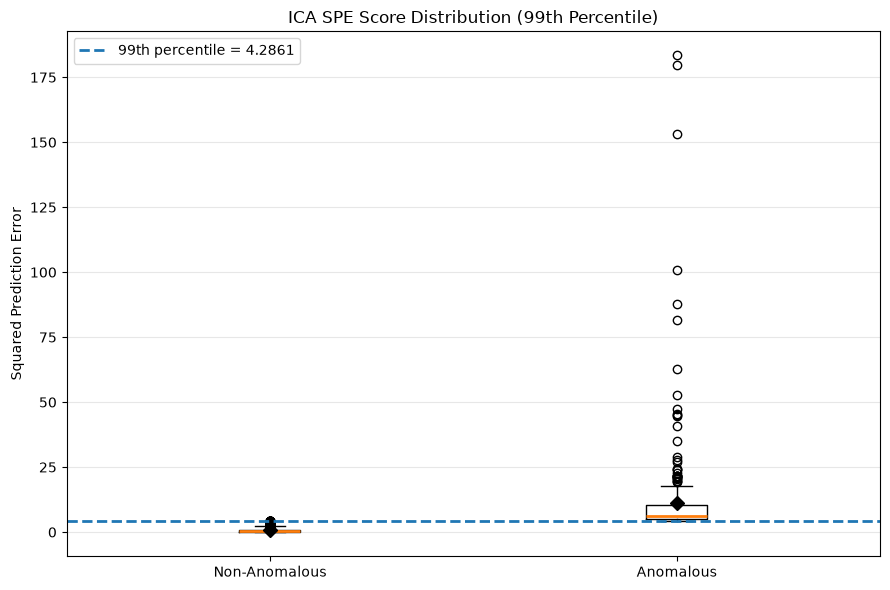

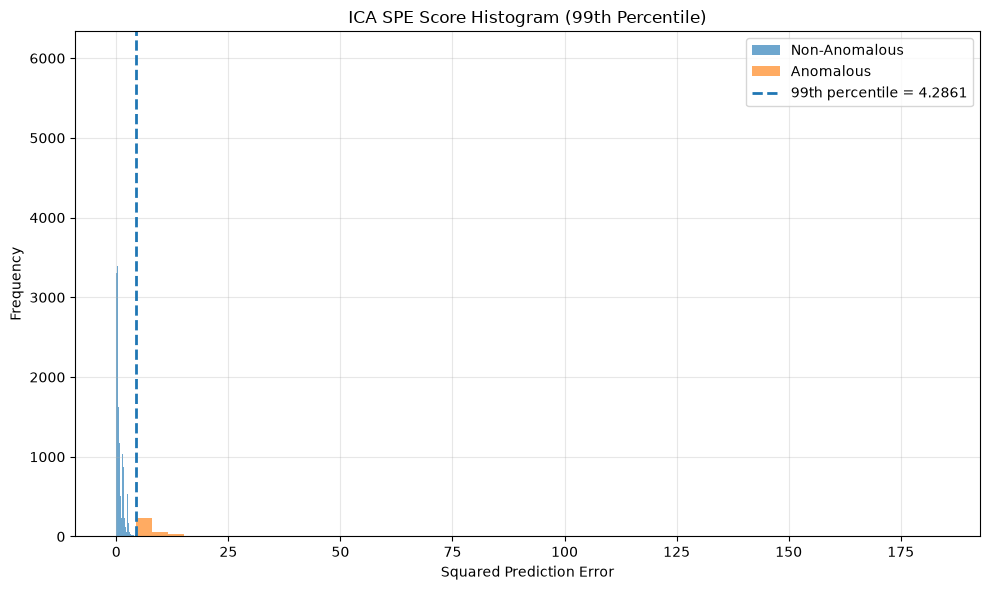


ICA SPE descriptive analysis completed successfully.


In [31]:
AnomalyAnalysis(ica_detection, "SPE", alpha=0.01).present()


**Observations**

Using the 1% criterion, ICA SPE flags 362 validation observations (1.00%) above the threshold of 4.2861. Their mean SPE is 11.022, compared with 0.691 for non-flagged observations, while their median is 6.281 versus 0.408. Compared with the 5% anomalous group, whose mean and median scores are 4.495 and 2.764, these transactions exhibit substantially larger reconstruction errors. The higher threshold selects a more extreme subset without changing the model or individual scores.

The main descriptive pattern is weaker profitability. Flagged transactions have a median benefit per order of −91.12, compared with 31.69 for non-flagged observations, and a median profit ratio of −1.65 versus 0.27. Approximately three-quarters have negative benefits, as their upper quartile is −41.38. Shipping discrepancies provide little overall separation: flagged transactions average approximately 0.60 days longer than scheduled, compared with 0.57 days for non-flagged transactions.

Relative to the 5% criterion, the 1% group therefore emphasizes more severe reconstruction failures associated with unusual financial profiles, while shipping discrepancies become less prominent. Mean sales is higher but median sales is lower than in the non-flagged group, indicating that some very large transactions influence the average. These statistics characterize the group; individual squared residuals are needed to identify the features contributing most to each transaction’s SPE.

## **5. Mahalanobis**

### **5.1 Squared Mahalanobis Distance ($D^2_M$)**

**1. What is Mahalanobis Distance?**

Mahalanobis Distance is a multivariate statistical measure that quantifies how far an observation is from the center of a dataset while accounting for the **variance of each feature and the correlations between features**.

Unlike Euclidean distance, which treats all directions equally, Mahalanobis Distance adjusts distances according to the covariance structure of the data.

For an observation $x_i$, the squared Mahalanobis Distance is defined as:

$$
\boxed{D_M^2(x_i)=(x_i-\mu)^T\Sigma^{-1}(x_i-\mu)}
$$

Where:

- $x_i$: feature vector of observation $i$.
- $\mu$: mean vector estimated from training data.
- $\Sigma$: covariance matrix estimated from training data.
- $\Sigma^{-1}$: inverse covariance matrix.

A larger distance indicates that an observation is farther from the center relative to the dataset's covariance structure, making it a potential anomaly.

**2. Metric: Squared Mahalanobis Distance ($D_M^2$)**

For this experiment, we will use **Squared Mahalanobis Distance** as the anomaly score.

Rather than reducing dimensionality, we will calculate the score using all **10 standardized numerical features** of the dataset.

Because the covariance matrix may be poorly conditioned, we can estimate it using the Ledoit–Wolf shrinkage estimator:

$$
\hat\Sigma_{\text{LW}}
=(1-\lambda)\hat\Sigma+\lambda\mu_{\Sigma}I
$$

Where:

- $\hat\Sigma$: empirical covariance matrix.
- $\mu_{\Sigma}=\operatorname{tr}(\hat\Sigma)/p$: average variance across the $p$ features.
- $\lambda$: estimated shrinkage intensity.
- $I$: identity matrix.

This regularization improves numerical stability when features are correlated.

The anomaly score becomes:

$$
\boxed{D_{M,i}^{2}=(z_i-\hat\mu)^T\hat\Sigma_{\text{LW}}^{-1}(z_i-\hat\mu)}
$$

Where $z_i$ is the standardized observation.

**3. Anomaly Detection Thresholds**

As with PCA and ICA, we will use empirical percentiles of the **training anomaly scores** to determine which observations are anomalous.

The threshold for significance level $\alpha$ is:

$$
\boxed{\tau_{\alpha}=Q_{1-\alpha}(D_{M,\text{train}}^2)}
$$

An observation is classified as anomalous when:

$$
D_{M,i}^2>\tau_{\alpha}
$$

We will evaluate two thresholds:

| Significance level | Training percentile | Interpretation |
|---|---|---|
| $\alpha=0.05$ | 95th | Flags observations exceeding the 95th percentile |
| $\alpha=0.01$ | 99th | Flags observations exceeding the 99th percentile |

The 99th-percentile threshold is more restrictive, identifying only observations with particularly large distances.

These are empirical detection thresholds, not guarantees of 5% or 1% false-positive rates, because the dataset does not contain verified anomaly labels.

### **5.2 Running Mahalanobis**

In [33]:
mahalanobis_detection = MahalanobisDetector().fit(data)
mahalanobis_detection.display()


MAHALANOBIS DISTANCE - MODEL FITTING
Features: 10
Covariance shrinkage: 0.000592
Fitting time: 0.01 seconds

Scoring time: 0.01 seconds

TRAINING MAHALANOBIS SCORES


count    108311.0000
mean          8.9773
std          25.9056
min           1.0337
25%           3.9396
50%           5.8853
75%           8.8223
max        3062.0705
Name: Mahalanobis_D2, dtype: float64


MAHALANOBIS THRESHOLDS


,Alpha,Percentile,Threshold,Training Anomaly Rate (%)
0,0.01,99.0,49.6896,1.0008
1,0.05,95.0,22.3223,5.0004



MAHALANOBIS DETECTION COMPARISON


,Dataset,Alpha,Observations,Anomalies,Anomaly Rate (%)
0,Training,0.01,108311,1084,1.0008
1,Training,0.05,108311,5416,5.0004
2,Validation,0.01,36104,349,0.9667
3,Validation,0.05,36104,1739,4.8166
4,Test,0.01,36104,336,0.9306
5,Test,0.05,36104,1763,4.8831



Results saved successfully.


,Mahalanobis_D2,Mahalanobis_Anomaly_Alpha_0_01,Mahalanobis_Anomaly_Alpha_0_05
105330,6.021782,False,False
111731,11.260389,False,False
26280,7.085251,False,False
2124,9.376852,False,False
34886,2.068900,False,False


### **5.3 Mahalanobis $D^2$ Analysis**

#### **5.3.1 Anomalies with $\alpha=0.05$**

MAHALANOBIS D² | 95TH PERCENTILE | VALIDATION
Threshold: 22.3223
Total observations: 36,104
Anomalous: 1,739
Non-anomalous: 34,365
Anomaly rate: 4.82%

MAHALANOBIS - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1739.0    3.5986    1.7340   
              Days for shipment (scheduled)   1739.0    2.8896    1.4054   
              Benefit per order               1739.0 -127.5361  310.2214   
              Sales per customer              1739.0  333.7468  284.5420   
              Order Item Discount             1739.0   39.3817   51.0397   
              Order Item Discount Rate        1739.0    0.1055    0.0796   
              Order Item Profit Ratio         1739.0   -0.8118    1.0872   
              Order Item Quantity             1739.0    3.0230    1.8210   
              Sales                           1739.0  373.1279  316.3628   
              Product Price                   1739.0  212.9745  330.6855   
Non-Anomalous Days for shipping (real)       34365.0    3.4976    1.6240   
              Days for shipment (scheduled)  34365.0    2.9306    1.3752   
              Benefit per order              34365.0   29.9856   69.1462   
              Sales per customer             34365.0  175.4053   98.5314   
              Order Item Discount            34365.0   19.6475   18.8927   
              Order Item Discount Rate       34365.0    0.1011    0.0700   
              Order Item Profit Ratio        34365.0    0.1687    0.3497   
              Order Item Quantity            34365.0    2.0660    1.4082   
              Sales                          34365.0  195.0525  108.1216   
              Product Price                  34365.0  138.5256  121.4790   

                                                 min     25%     50%      75%  \
Group         Feature                                                           
Anomalous     Days for shipping (real)          0.00    2.00    4.00    5.000   
              Days for shipment (scheduled)     0.00    2.00    4.00    4.000   
              Benefit per order             -2205.00 -316.55  -72.00  103.965   
              Sales per customer                8.66  106.59  331.97  433.580   
              Order Item Discount               0.00    5.47   20.00   59.990   
              Order Item Discount Rate          0.00    0.03    0.09    0.170   
              Order Item Profit Ratio          -2.75   -1.70   -0.70    0.280   
              Order Item Quantity               1.00    1.00    4.00    5.000   
              Sales                            11.29  124.95  399.96  499.950   
              Product Price                     9.99   50.00   99.99  199.990   
Non-Anomalous Days for shipping (real)          0.00    2.00    3.00    5.000   
              Days for shipment (scheduled)     0.00    2.00    4.00    4.000   
              Benefit per order              -431.97    8.68   32.16   64.550   
              Sales per customer                8.29  103.99  160.00  239.980   
              Order Item Discount               0.00    5.40   14.00   28.000   
              Order Item Discount Rate          0.00    0.04    0.09    0.160   
              Order Item Profit Ratio          -1.80    0.08    0.28    0.360   
              Order Item Quantity               1.00    1.00    1.00    3.000   
              Sales                             9.99  119.98  189.00  260.650   
              Product Price                     9.99   50.00   59.99  199.990   

                                                 max  
Group         Feature                                 
Anomalous     Days for shipping (real)          6.00  
              Days for shipment (scheduled)     4.00  
              Benefit per order               720.00  
              Sales per customer             1679.99  
              Order Item Discount             500.00  
              Order Item Discount Rate          0.25  
              Order Item Profit Ratio           0.50  
              Order Item Quantity               5.00  
              Sales                      


MAHALANOBIS - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1739.0000,34365.0000
mean,52.1094,6.6503
std,83.7554,3.9204
min,22.3333,1.0412
25%,26.8575,3.8793
50%,34.0992,5.6587
75%,44.8151,8.3438
max,1419.9305,22.3213


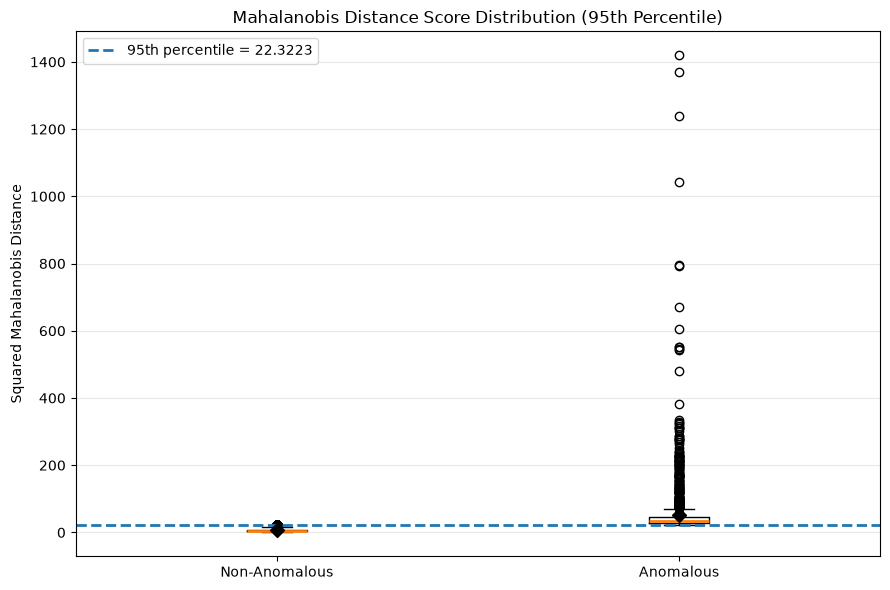

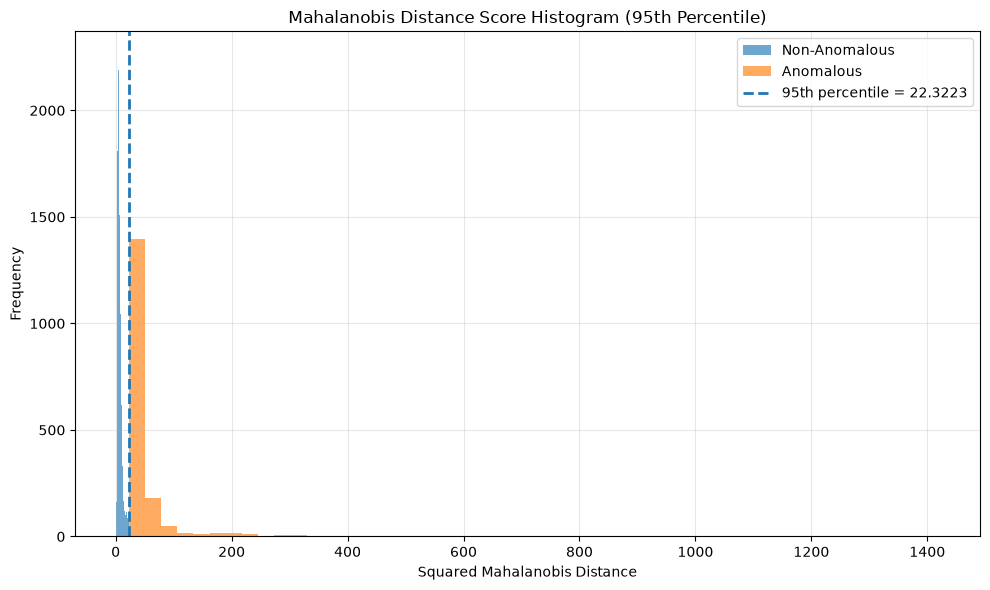


Mahalanobis descriptive analysis completed successfully.


In [34]:
AnomalyAnalysis(mahalanobis_detection, "D2", alpha=0.05).present()


**Observations**

Using the 5% criterion, squared Mahalanobis distance flags 1,739 validation observations (4.82%) above the training-derived threshold of 22.3223. Their mean score is 52.109, compared with 6.650 for non-flagged observations, while their median is 34.099 versus 5.659. These higher scores indicate greater distance from the estimated training-data center after accounting for feature variances and correlations. The maximum score of 1,419.931 reveals an exceptionally extreme multivariate observation.

The flagged transactions are characterized by higher transaction values, larger purchased quantities, and weaker profitability. Median sales is 399.96 versus 189.00, and median sales per customer is 331.97 versus 160.00. Median quantity increases from one to four items. Meanwhile, median benefit per order decreases from 32.16 to −72.00, and median profit ratio falls from 0.28 to −0.70. Product prices and absolute discounts are also higher among flagged observations.

Flagged observations have higher median sales and quantities and lower median profitability than non-flagged observations. These differences describe the group, but further analysis is needed to determine which features or relationships drive individual Mahalanobis scores However, the flagged group also contains profitable transactions, so losses do not explain every detection. Individual multivariate contributions require further examination, and high distances indicate statistical atypicality rather data errors or possible frauds.

#### **5.3.2 Anomalies with $\alpha=0.01$**

MAHALANOBIS D² | 99TH PERCENTILE | VALIDATION
Threshold: 49.6896
Total observations: 36,104
Anomalous: 349
Non-anomalous: 35,755
Anomaly rate: 0.97%

MAHALANOBIS - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         349.0    3.6304    1.6929   
              Days for shipment (scheduled)    349.0    3.0487    1.3393   
              Benefit per order                349.0 -289.8545  495.4313   
              Sales per customer               349.0  547.4961  492.0785   
              Order Item Discount              349.0   65.5003   87.0607   
              Order Item Discount Rate         349.0    0.1054    0.0797   
              Order Item Profit Ratio          349.0   -1.4019    1.1956   
              Order Item Quantity              349.0    1.9570    1.5521   
              Sales                            349.0  612.9961  549.3115   
              Product Price                    349.0  530.3726  593.6833   
Non-Anomalous Days for shipping (real)       35755.0    3.5012    1.6289   
              Days for shipment (scheduled)  35755.0    2.9275    1.3770   
              Benefit per order              35755.0   25.4462   84.0957   
              Sales per customer             35755.0  179.4745  103.7367   
              Order Item Discount            35755.0   20.1597   19.8512   
              Order Item Discount Rate       35755.0    0.1013    0.0704   
              Order Item Profit Ratio        35755.0    0.1363    0.4275   
              Order Item Quantity            35755.0    2.1136    1.4443   
              Sales                          35755.0  199.6340  113.9313   
              Product Price                  35755.0  138.3218  121.8166   

                                                 min     25%     50%  \
Group         Feature                                                  
Anomalous     Days for shipping (real)          0.00    2.00    4.00   
              Days for shipment (scheduled)     0.00    2.00    4.00   
              Benefit per order             -2205.00 -661.47 -286.97   
              Sales per customer                9.23  248.98  377.98   
              Order Item Discount               0.00    8.00   25.38   
              Order Item Discount Rate          0.00    0.03    0.09   
              Order Item Profit Ratio          -2.75   -2.55   -1.65   
              Order Item Quantity               1.00    1.00    1.00   
              Sales                            11.54  299.95  399.98   
              Product Price                     9.99   99.99  299.98   
Non-Anomalous Days for shipping (real)          0.00    2.00    3.00   
              Days for shipment (scheduled)     0.00    2.00    4.00   
              Benefit per order              -665.51    7.50   31.67   
              Sales per customer                8.29  103.99  163.98   
              Order Item Discount               0.00    5.40   14.00   
              Order Item Discount Rate          0.00    0.04    0.09   
              Order Item Profit Ratio          -2.75    0.08    0.27   
              Order Item Quantity               1.00    1.00    1.00   
              Sales                             9.99  119.98  199.92   
              Product Price                     9.99   50.00   59.99   

                                                  75%      max  
Group         Feature                                           
Anomalous     Days for shipping (real)          5.000     6.00  
              Days for shipment (scheduled)     4.000     4.00  
              Benefit per order                46.870   720.00  
              Sales per customer             1125.000  1679.99  
              Order Item Discount              89.990   500.00  
              Order Item Discount Rate          0.170     0.25  
              Order Item Profit Ratio           0.040     0.50  
              Order Item Quantity               2.000     5.00  
              Sales                          1500.000  1999.99  
              Product Price                  1500.000  1999.99  
Non-Anoma


MAHALANOBIS - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,349.0000,35755.0000
mean,131.3882,7.6437
std,164.1357,6.4186
min,49.8201,1.0412
25%,57.3726,3.9405
50%,70.9798,5.8477
75%,144.6750,8.7711
max,1419.9305,49.6872


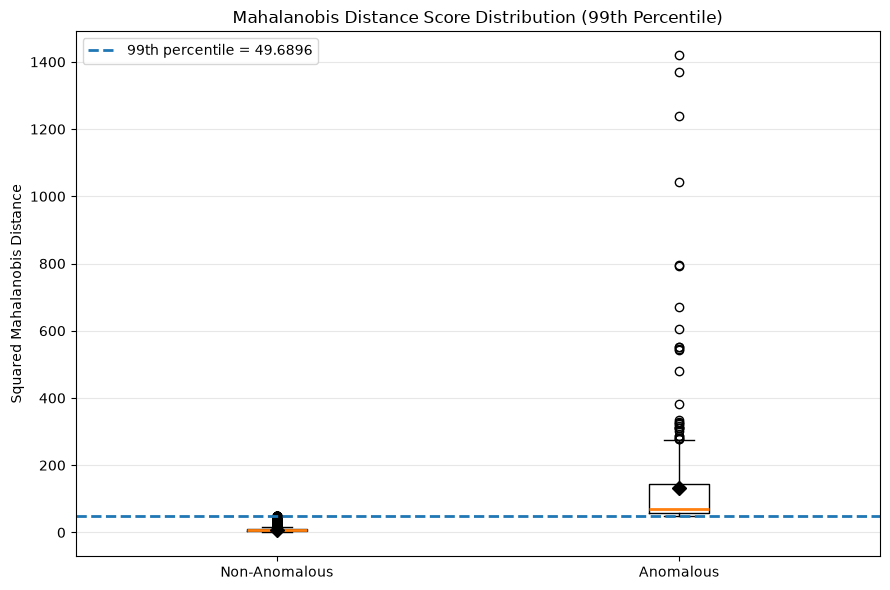

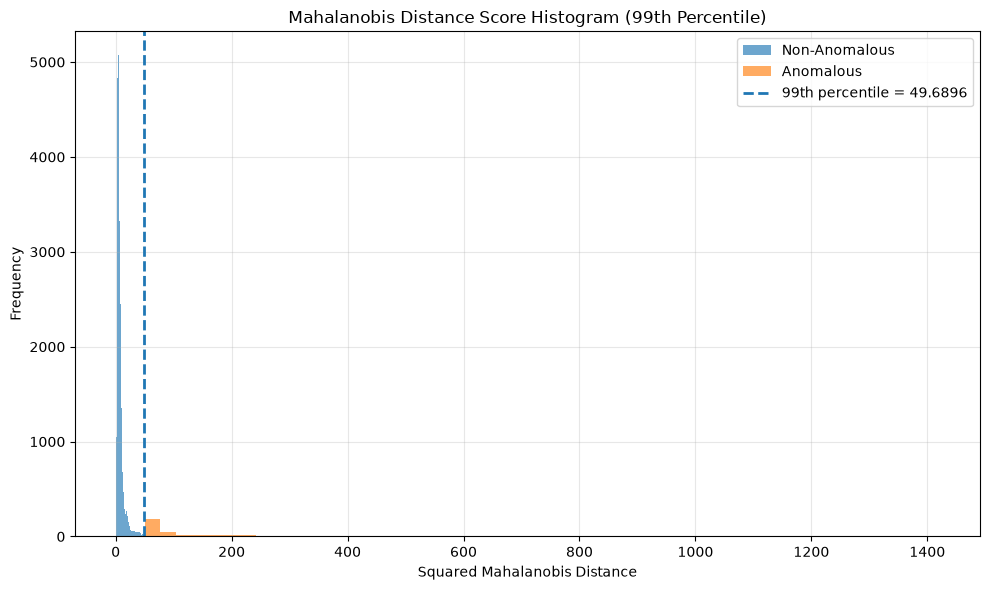


Mahalanobis descriptive analysis completed successfully.


In [35]:
AnomalyAnalysis(mahalanobis_detection, "D2", alpha=0.01).present()


**Observations**

Using the 1% criterion increases the squared Mahalanobis threshold from 22.3223 to 49.6896, reducing flagged validation observations from 1,739 (4.82%) to 349 (0.97%). These observations form a subset of those identified at 5%. Their mean score increases from 52.109 to 131.388, while their median rises from 34.099 to 70.980. This indicates greater multivariate distance from the estimated training-data center, accounting for feature variances and correlations.

The selected group exhibits more negative median profitability: benefit per order decreases from −72.00 to −286.97, and profit ratio declines from −0.70 to −1.65. Median product price increases from 99.99 to 299.98. However, median sales remains approximately 400, while median quantity decreases from four items to one. The stricter criterion therefore does not uniformly select larger purchases; it selects a different mix of more extreme numerical profiles.

The 1% criterion concentrates on observations farther from the estimated global covariance structure, whereas the 5% criterion includes a broader range of moderately unusual transactions. These descriptive differences do not establish which features drive each individual score, since Mahalanobis distance evaluates all ten features jointly. Higher scores indicate statistical atypicality, rather than confirmed errors or fraud.

## **6. Local Outlier Factory (LOF)**

### **6.1 Notation**

Local Outlier Factor (LOF) is an unsupervised anomaly detection algorithm that identifies observations whose local density is substantially lower than that of their nearest neighbors.

Unlike global anomaly detection methods, LOF evaluates observations relative to their local neighborhoods, allowing it to detect anomalies in regions with different densities.

The main hyperparameter is $k$, representing the number of nearest neighbors used to estimate local density.

**1. Reachability distance**

For an observation $x_i$ and one of its neighbors $x_j$:
$
\operatorname{reachdist}_k(x_i,x_j)=\max\{d_k(x_j),d(x_i,x_j)\}
$

where $d_k(x_j)$ is the distance from $x_j$ to its $k$-th nearest neighbor.

**2. Local reachability density (LRD)**

$
LRD_k(x_i)=\left(\frac{1}{|N_k(x_i)|}\sum_{x_j\in N_k(x_i)}\operatorname{reachdist}_k(x_i,x_j)\right)^{-1}
$

This estimates the local density around an observation. Lower LRD values indicate more isolated observations.

**3. LOF anomaly score**

$
\boxed{LOF_k(x_i)=\frac{1}{|N_k(x_i)|}\sum_{x_j\in N_k(x_i)}\frac{LRD_k(x_j)}{LRD_k(x_i)}}
$

The score compares the observation's local density with the average density of its neighbors.
- LOF ≈ 1: Similar local density; likely normal.
- LOF > 1: Lower local density; potentially anomalous.
- LOF < 1: Higher local density than its neighbors.

**Hyperparameter evaluation**


| Metric | Mathematical Definition | Purpose |
|---|---|---|
| **Score Dispersion** | $\sigma_{LOF} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(s_i-\bar{s})^2}$ | Describes variability in anomaly scores. |
| **Upper Quantiles** | $Q_{0.95}(S),\ Q_{0.99}(S)$ | Characterizes extreme anomaly scores. |
| **Spearman Correlation** | $\rho_s = \operatorname{corr}(\operatorname{rank}(S_{k_1}),\operatorname{rank}(S_{k_2}))$ | Evaluates ranking consistency across different values of $k$. |
| **Top-1% Jaccard Similarity** | $J(A,B) = \frac{\lvert A \cap B \rvert}{\lvert A \cup B \rvert}$ | Measures agreement among the highest-scoring 1% of observations. |
| **Execution Time** | $t_k = t_{\mathrm{end}} - t_{\mathrm{start}}$ | Evaluates computational cost. |

Here, $S_k$ represents the validation anomaly scores obtained using neighborhood size $k$, while $A$ and $B$ represent the sets containing the top 1% highest-scoring validation observations for two different configurations.

Selection criterion: We prioritize configurations with consistent anomaly rankings and high overlap among extreme observations, while examining score distributions and computational cost. These metrics measure sensitivity to $k$, not anomaly detection accuracy.

After selecting $k$, we will independently evaluate training-sample stability to determine whether the anomaly rankings remain consistent when the training data changes.

### **6.2 Hyperparameter Search (n_neighbors)**

In [39]:
lof_search = LOFSearch().run(data)


LOF - HYPERPARAMETER EVALUATION
Training observations: 108,311
Validation observations: 36,104
Number of features: 10
Neighborhood sizes: [10, 20, 30, 50]

Evaluating LOF with k = 10
Execution time: 2.25 seconds
Mean LOF score: 78365.5354
Score standard deviation: 8964993.3871

Evaluating LOF with k = 20
Execution time: 2.99 seconds
Mean LOF score: 1.0824
Score standard deviation: 0.1893

Evaluating LOF with k = 30
Execution time: 3.74 seconds
Mean LOF score: 1.0740
Score standard deviation: 0.1474

Evaluating LOF with k = 50
Execution time: 4.81 seconds
Mean LOF score: 1.0675
Score standard deviation: 0.1206

LOF - SCORE DISTRIBUTION AND COMPUTATIONAL METRICS


,K,Score Mean,Score Std,Score Median,Score Min,Score Max,Score P95,Score P99,Execution Time (s)
0,10,78365.5354,8.964993e+06,1.0350,0.8400,1.621760e+09,1.5029,2.3304,2.2495
1,20,1.0824,1.893000e-01,1.0317,0.8874,8.236300e+00,1.3295,1.8531,2.9851
2,30,1.0740,1.474000e-01,1.0312,0.9005,4.816600e+00,1.2921,1.7155,3.7374
3,50,1.0675,1.206000e-01,1.0327,0.8975,2.838600e+00,1.2674,1.5862,4.8087



LOF - NEIGHBORHOOD SENSITIVITY


,K1,K2,K Pair,Spearman,Top 1% Jaccard
0,10,20,10 vs 20,0.5682,0.3140
1,20,30,20 vs 30,0.8141,0.6018
2,30,50,30 vs 50,0.8111,0.4113



SPEARMAN CORRELATION MATRIX


,10,20,30,50
10,1.0000,0.5682,0.4591,0.3425
20,0.5682,1.0000,0.8141,0.6221
30,0.4591,0.8141,1.0000,0.8111
50,0.3425,0.6221,0.8111,1.0000



TOP-1% JACCARD MATRIX


,10,20,30,50
10,1.0000,0.3140,0.2168,0.1104
20,0.3140,1.0000,0.6018,0.2769
30,0.2168,0.6018,1.0000,0.4113
50,0.1104,0.2769,0.4113,1.0000



LOF HYPERPARAMETER EVALUATION COMPLETED
Results saved in: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/06_anomaly_detection


### **6.3 Metrics Visualization**

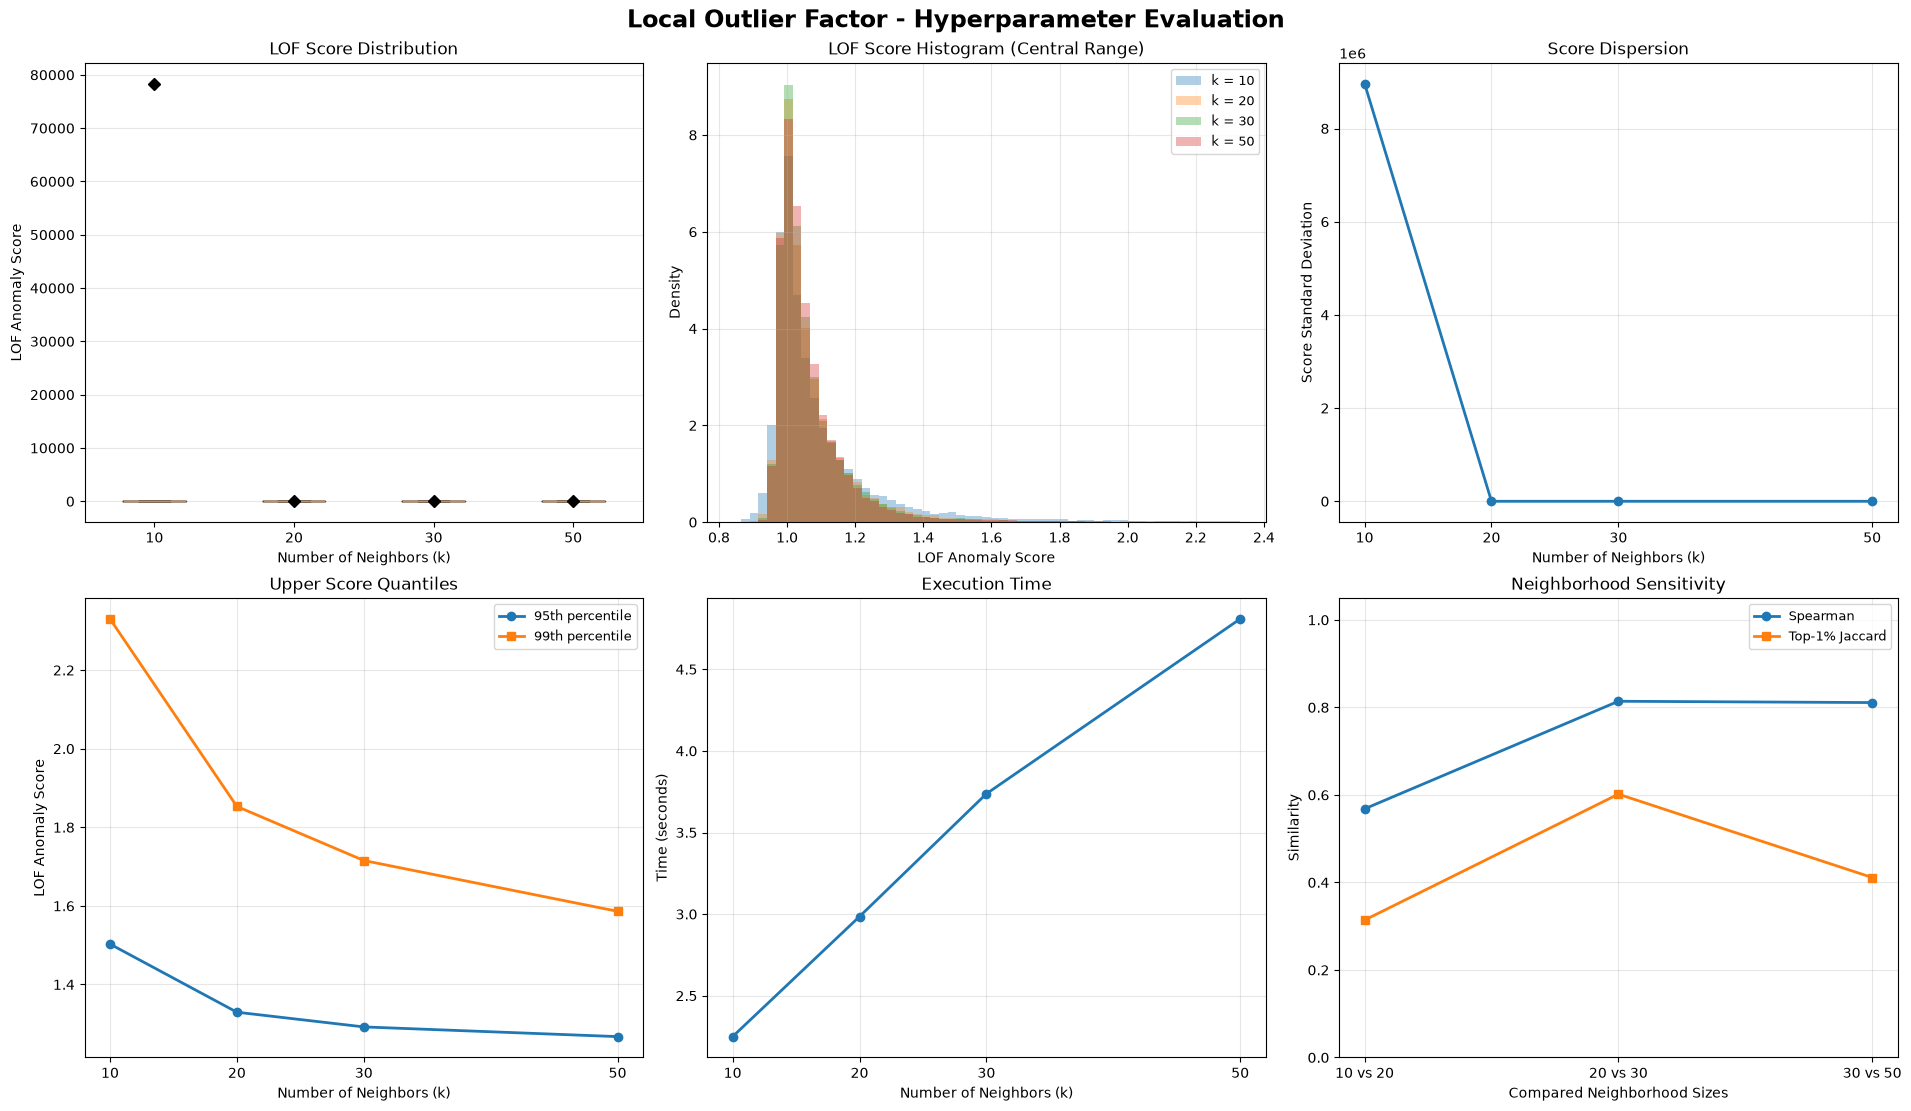

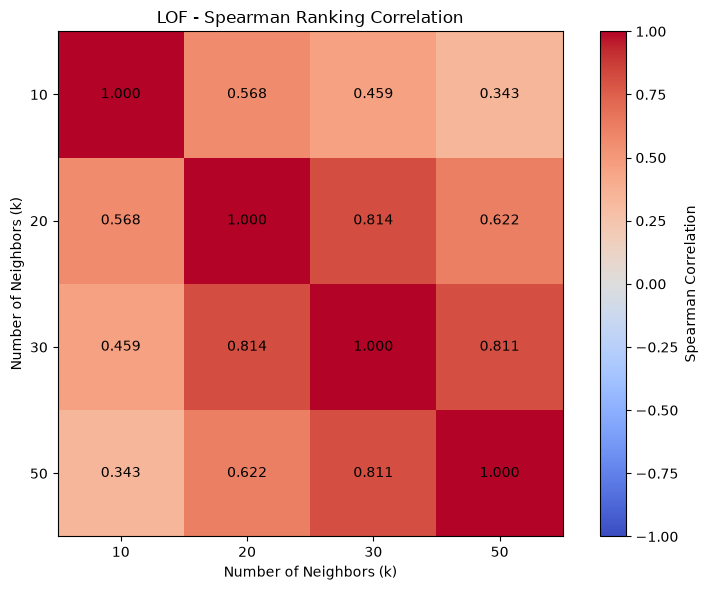

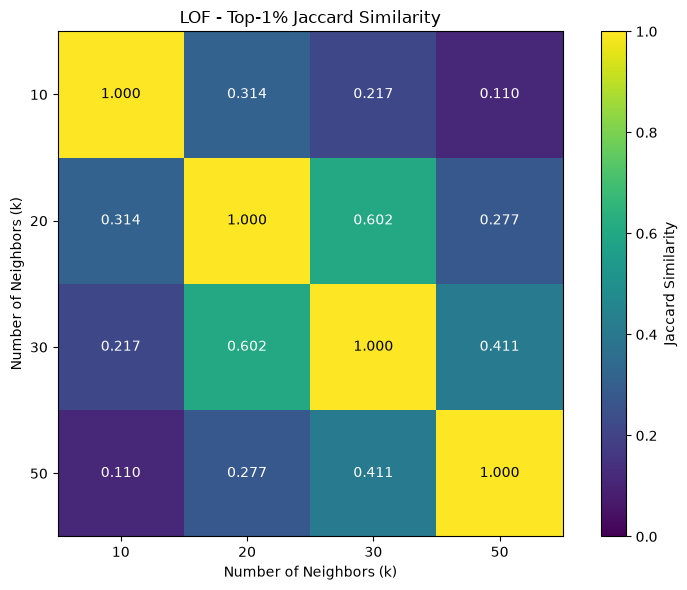


All LOF evaluation figures saved successfully.


In [41]:
plot_lof_search(lof_search)


**Observations**

We selected **$\text{n\_neighbours}=20$** for the Local Outlier Factor (LOF) model based on the hyperparameter sensitivity analysis. Compared with $\text{n\_neighbours}=30$, this configuration achieved a **Spearman correlation of approximately 0.81** and a **Top-1% Jaccard similarity of 0.60**, indicating relatively consistent anomaly rankings and substantial overlap among the most anomalous observations. Additionally, $\text{n\_neighbours}=20$ exhibited substantially less extreme score dispersion than $\text{n\_neighbours}=10$. Although $\text{n\_neighbours}=30$ demonstrated comparable consistency, we preferred $\text{n\_neighbours}=20$ because our objective is to **detect local outliers**, and a smaller neighborhood preserves greater sensitivity to localized density differences, whereas larger neighborhoods may smooth out these patterns. Therefore, $\text{n\_neighbours}=20$ represents a reasonable balance between ranking consistency, computational efficiency, and sensitivity to local anomalies.

### **6.4 Seed Stability of LOF with n_neighbors=20**

In [43]:
lof_stability = LOFStability(n_neighbors=20, train_fraction=0.8).run(data)


Evaluating seed 0...
Evaluating seed 21...
Evaluating seed 42...
Evaluating seed 123...
Evaluating seed 7...
Evaluating seed 13...
Evaluating seed 57...
Evaluating seed 99...
Evaluating seed 202...
Evaluating seed 314...

LOF results by seed:


,Seed,Training Observations,Validation Observations,Execution Time (s),Score Mean,Score Median,Score Std,Score P99,Score Max
0,0,86648,36104,2.3377,1.0805,1.0324,0.1673,1.8102,6.0100
1,21,86648,36104,2.3707,1.0802,1.0331,0.1646,1.8072,5.6026
2,42,86648,36104,4.5884,1.0798,1.0331,0.1646,1.7829,6.1112
3,123,86648,36104,4.8766,1.0811,1.0335,0.1676,1.8245,5.9070
4,7,86648,36104,4.8014,1.0820,1.0338,0.1694,1.8059,5.9613
5,13,86648,36104,4.1111,1.0800,1.0335,0.1635,1.7881,5.8769
6,57,86648,36104,3.8328,1.0805,1.0329,0.1700,1.8169,6.3674
7,99,86648,36104,3.6957,1.0807,1.0330,0.1662,1.8100,5.9776
8,202,86648,36104,3.6009,1.0802,1.0332,0.1658,1.8076,5.8583
9,314,86648,36104,3.5566,1.0800,1.0330,0.1651,1.8025,5.5840



Pairwise seed stability:


,Seed 1,Seed 2,Seed Pair,Spearman,Top 1% Jaccard
0,0,21,0 vs 21,0.9068,0.7238
1,0,42,0 vs 42,0.9090,0.7156
2,0,123,0 vs 123,0.9054,0.6876
3,0,7,0 vs 7,0.9067,0.7035
4,0,13,0 vs 13,0.9039,0.6798
5,0,57,0 vs 57,0.9086,0.7197
6,0,99,0 vs 99,0.9062,0.7075
7,0,202,0 vs 202,0.9037,0.6995
8,0,314,0 vs 314,0.9085,0.7075
9,21,42,21 vs 42,0.9061,0.7279



Overall seed stability:


,Metric,Mean,Std,Min,Max
0,Spearman,0.9076,0.0019,0.9037,0.9121
1,Top 1% Jaccard,0.7076,0.0141,0.6721,0.7404



Score variability across seeds:


,Mean Score,Score Std,Score CV
count,36104.0000,36104.0000,36104.0000
mean,1.0805,0.0245,0.0210
std,0.1621,0.0288,0.0184
min,0.9121,0.0008,0.0008
25%,1.0008,0.0098,0.0097
50%,1.0350,0.0165,0.0158
75%,1.1022,0.0290,0.0262
max,5.9256,0.8631,0.3544



LOF seed stability evaluation completed.


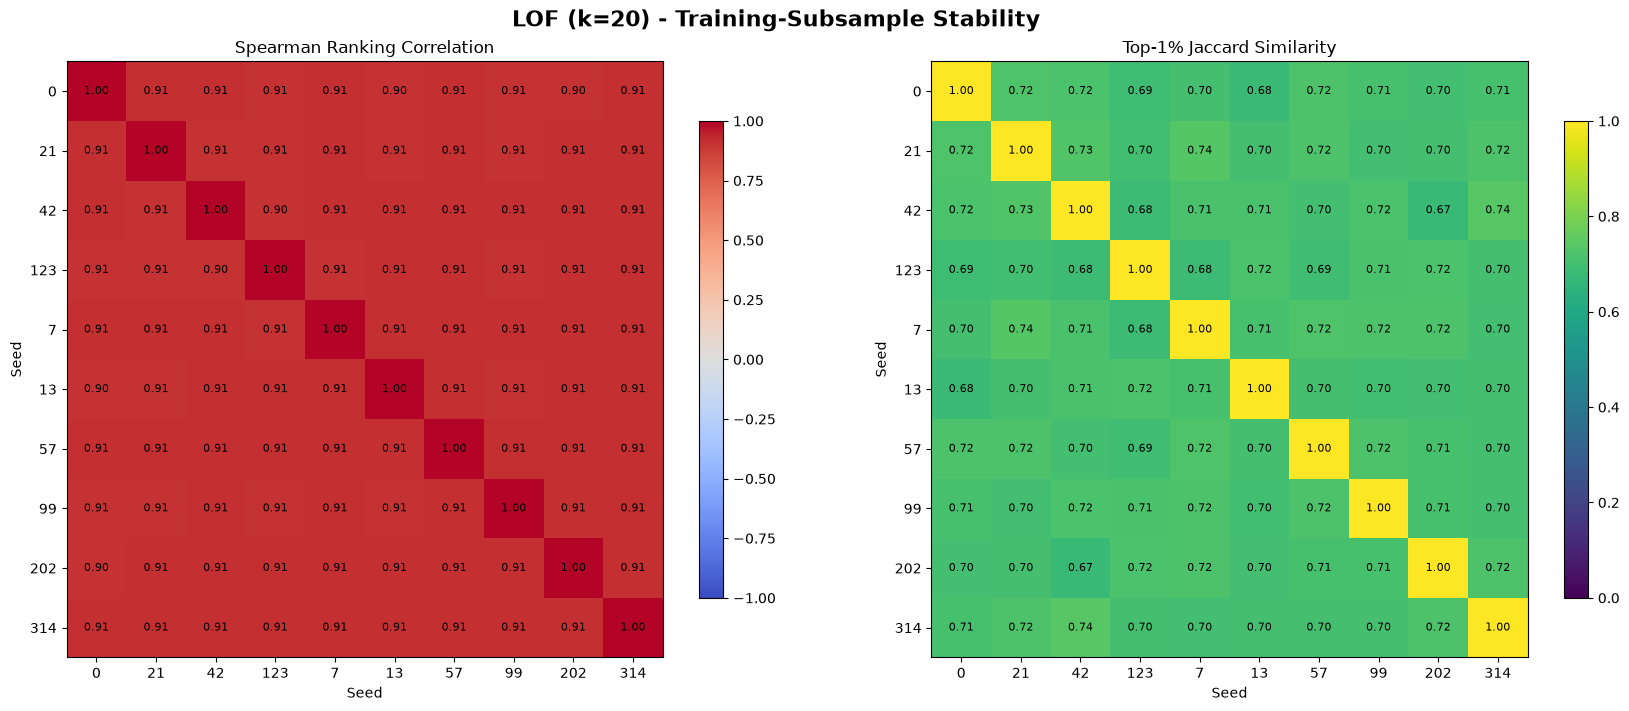

In [44]:
plot_lof_stability(lof_stability)


**Observations**

The LOF model with $\text{n\_neighbors}=20$ demonstrated **consistent anomaly detection across different random seeds**. The Spearman ranking correlations remained approximately 0.90–0.91, indicating strong consistency in the overall anomaly rankings despite changes in the training subsamples. Additionally, the Top-1% Jaccard similarities ranged from approximately 0.67 to 0.74, showing substantial overlap among the observations identified as most anomalous. These results suggest that LOF maintains relatively stable anomaly rankings and consistently identifies many of the same extreme observations across different training subsamples, supporting the robustness of the selected configuration.

### **6.5 Detecting Anomalies with LOF**

#### **6.5.1 LOF with n_neighbors=20**

In [45]:
lof_detection = LOFDetector(n_neighbors=20).fit(data)
lof_detection.display()


LOF fitted with k = 20
Training observations: 108,311
Fit time: 2.83 seconds

Empirical LOF thresholds:


,Alpha,Quantile,Threshold
0,0.01,0.99,1.870425
1,0.05,0.95,1.322417



LOF anomaly detection summary:


,Dataset,Alpha,Observations,Anomalies,Anomaly Rate (%),Score Mean,Score Median,Score P95,Score P99,Score Max
0,Train,0.01,108311,1084,1.0008,1.0791,1.0268,1.3224,1.8704,9.0293
1,Train,0.05,108311,5416,5.0004,1.0791,1.0268,1.3224,1.8704,9.0293
2,Validation,0.01,36104,350,0.9694,1.0824,1.0317,1.3295,1.8531,8.2363
3,Validation,0.05,36104,1891,5.2376,1.0824,1.0317,1.3295,1.8531,8.2363



Final LOF model and results saved successfully.


#### **6.5.2 Anomalies with $\alpha=0.05$**

LOF (k=20) | 95TH PERCENTILE | VALIDATION
Threshold: 1.3224
Total observations: 36,104
Anomalous: 1,891
Non-anomalous: 34,213
Anomaly rate: 5.24%

LOF - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1891.0    3.4045    1.6365   
              Days for shipment (scheduled)   1891.0    2.9170    1.4078   
              Benefit per order               1891.0   20.7860  118.5831   
              Sales per customer              1891.0  198.3341  157.4474   
              Order Item Discount             1891.0   27.5037   32.9563   
              Order Item Discount Rate        1891.0    0.1201    0.0813   
              Order Item Profit Ratio         1891.0    0.1305    0.4222   
              Order Item Quantity             1891.0    1.4336    1.0143   
              Sales                           1891.0  225.8371  178.2759   
              Product Price                   1891.0  201.7103  185.0407   
Non-Anomalous Days for shipping (real)       34213.0    3.5079    1.6291   
              Days for shipment (scheduled)  34213.0    2.9293    1.3749   
              Benefit per order              34213.0   22.4874  100.5728   
              Sales per customer             34213.0  182.1862  117.0236   
              Order Item Discount            34213.0   20.2163   21.1404   
              Order Item Discount Rate       34213.0    0.1003    0.0697   
              Order Item Profit Ratio        34213.0    0.1210    0.4686   
              Order Item Quantity            34213.0    2.1496    1.4564   
              Sales                          34213.0  202.4023  128.7492   
              Product Price                  34213.0  138.8174  136.1887   

                                                 min      25%     50%     75%  \
Group         Feature                                                           
Anomalous     Days for shipping (real)          0.00    2.000    3.00    5.00   
              Days for shipment (scheduled)     0.00    2.000    4.00    4.00   
              Benefit per order             -1844.98    1.005   27.90   65.07   
              Sales per customer                8.47   95.980  161.87  292.82   
              Order Item Discount               0.00    5.210   18.00   40.00   
              Order Item Discount Rate          0.00    0.050    0.12    0.18   
              Order Item Profit Ratio          -2.70    0.020    0.26    0.39   
              Order Item Quantity               1.00    1.000    1.00    1.00   
              Sales                             9.99   99.990  199.98  327.75   
              Product Price                     9.99   80.000  129.99  299.98   
Non-Anomalous Days for shipping (real)          0.00    2.000    3.00    5.00   
              Days for shipment (scheduled)     0.00    2.000    4.00    4.00   
              Benefit per order             -2205.00    7.460   31.50   64.89   
              Sales per customer                8.29  104.380  163.99  245.99   
              Order Item Discount               0.00    5.400   14.00   28.80   
              Order Item Discount Rate          0.00    0.040    0.09    0.16   
              Order Item Profit Ratio          -2.75    0.080    0.27    0.36   
              Order Item Quantity               1.00    1.000    1.00    3.00   
              Sales                             9.99  119.980  199.92  299.95   
              Product Price                     9.99   50.000   59.99  199.99   

                                                 max  
Group         Feature                                 
Anomalous     Days for shipping (real)          6.00  
              Days for shipment (scheduled)     4.00  
              Benefit per order               520.00  
              Sales per customer             1679.99  
              Order Item Discount             500.00  
              Order Item Discount Rate          0.25  
              Order Item Profit Ratio           0.50  
              Order Item Quantity               5.00  
              Sales                      


LOF - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1891.0000,34213.0000
mean,1.6475,1.0512
std,0.4923,0.0762
min,1.3226,0.8874
25%,1.3759,0.9965
50%,1.4778,1.0275
75%,1.7241,1.0860
max,8.2363,1.3224


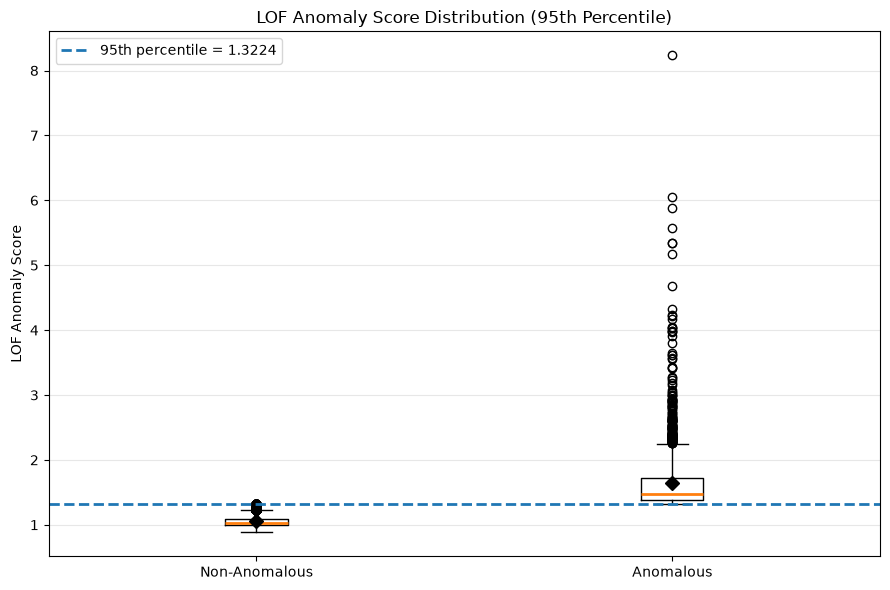

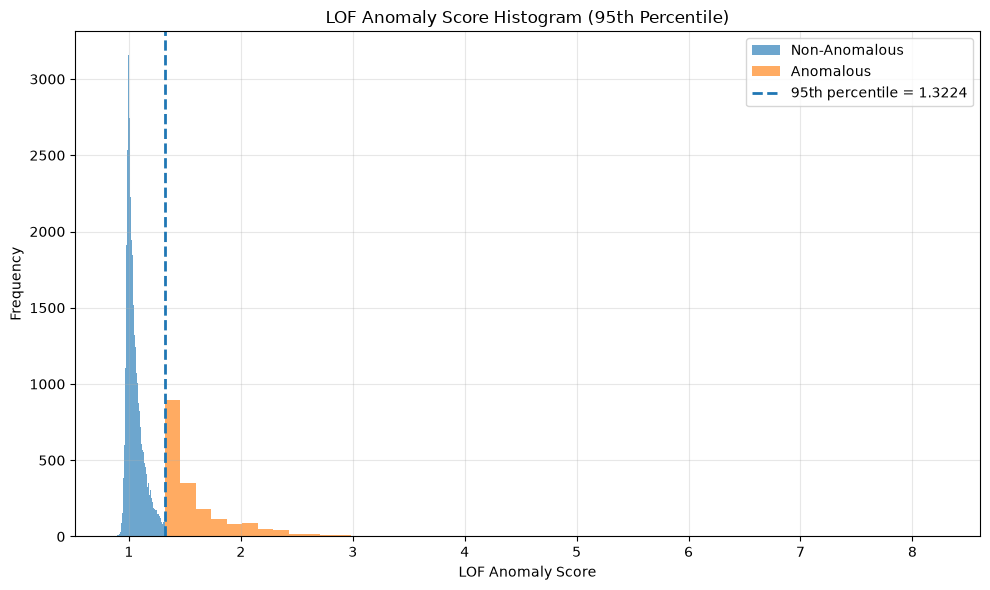


LOF descriptive analysis completed successfully.


In [47]:
AnomalyAnalysis(lof_detection, "LOF", alpha=0.05).present()


**Observations**

Using 20 neighbors and the 5% criterion, LOF flags 1,891 validation observations (5.24%) above the training-derived threshold of 1.3224. Their mean score is 1.6475, compared with 1.0512 for non-flagged observations, while their median is 1.4778 versus 1.0275. Higher scores indicate lower density relative to neighboring training observations. Although this comparison is local, LOF can identify both locally unusual transactions and globally isolated observations.

The flagged group has a higher median product price, at 129.99 compared with 59.99 for non-flagged transactions. Median absolute discount and discount rate are also higher, whereas median sales, profitability, quantities, and shipping durations show relatively little separation. These aggregate statistics may combine different outlier profiles, concealing patterns that are visible only within particular neighborhoods or individual transactions.

Consequently, the descriptive tables alone cannot determine whether the flagged observations are predominantly local or global outliers. Interpretation requires examining their reference neighborhoods and their positions relative to the wider dataset. Results also depend on neighborhood size: changing the number of neighbors can alter the scores and detections. High LOF scores establish density contrast under the selected configuration, rather than confirmed fraud or data errors.

#### **6.5.3 Anomalies with $\alpha=0.01$**

LOF (k=20) | 99TH PERCENTILE | VALIDATION
Threshold: 1.8704
Total observations: 36,104
Anomalous: 350
Non-anomalous: 35,754
Anomaly rate: 0.97%

LOF - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         350.0    3.5286    1.5377   
              Days for shipment (scheduled)    350.0    3.2171    1.3041   
              Benefit per order                350.0   59.7725  130.6075   
              Sales per customer               350.0  254.2505  159.7574   
              Order Item Discount              350.0   35.5730   44.1477   
              Order Item Discount Rate         350.0    0.1252    0.0765   
              Order Item Profit Ratio          350.0    0.2758    0.2180   
              Order Item Quantity              350.0    1.0714    0.4941   
              Sales                            350.0  289.8229  192.4950   
              Product Price                    350.0  286.0349  195.0481   
Non-Anomalous Days for shipping (real)       35754.0    3.5022    1.6305   
              Days for shipment (scheduled)  35754.0    2.9258    1.3771   
              Benefit per order              35754.0   22.0325  101.2033   
              Sales per customer             35754.0  182.3348  118.8634   
              Order Item Discount            35754.0   20.4514   21.5984   
              Order Item Discount Rate       35754.0    0.1011    0.0704   
              Order Item Profit Ratio        35754.0    0.1200    0.4678   
              Order Item Quantity            35754.0    2.1223    1.4480   
              Sales                          35754.0  202.7860  130.8983   
              Product Price                  35754.0  140.7027  138.4922   

                                                 min       25%     50%  \
Group         Feature                                                    
Anomalous     Days for shipping (real)          1.00    2.0000    3.00   
              Days for shipment (scheduled)     0.00    2.0000    4.00   
              Benefit per order             -1844.98   31.2650   60.43   
              Sales per customer               23.99  144.1550  234.59   
              Order Item Discount               0.00   15.2500   25.00   
              Order Item Discount Rate          0.00    0.0600    0.13   
              Order Item Profit Ratio          -2.05    0.1725    0.31   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                            31.98  164.3800  260.65   
              Product Price                    15.99  164.3800  260.65   
Non-Anomalous Days for shipping (real)          0.00    2.0000    3.00   
              Days for shipment (scheduled)     0.00    2.0000    4.00   
              Benefit per order             -2205.00    6.7900   31.18   
              Sales per customer                8.29  103.9900  163.99   
              Order Item Discount               0.00    5.4000   14.00   
              Order Item Discount Rate          0.00    0.0400    0.09   
              Order Item Profit Ratio          -2.75    0.0700    0.27   
              Order Item Quantity               1.00    1.0000    1.00   
              Sales                             9.99  119.9800  199.92   
              Product Price                     9.99   50.0000   59.99   

                                                75%      max  
Group         Feature                                         
Anomalous     Days for shipping (real)         5.00     6.00  
              Days for shipment (scheduled)    4.00     4.00  
              Benefit per order              103.58   520.00  
              Sales per customer             337.46  1599.99  
              Order Item Discount             45.20   500.00  
              Order Item Discount Rate         0.18     0.25  
              Order Item Profit Ratio          0.42     0.50  
              Order Item Quantity              1.00     5.00  
              Sales                          357.10  1999.99  
              Product Price                  357.10 


LOF - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,350.0000,35754.0000
mean,2.4041,1.0695
std,0.7235,0.1175
min,1.8708,0.8874
25%,2.0202,0.9975
50%,2.1662,1.0309
75%,2.4742,1.0983
max,8.2363,1.8695


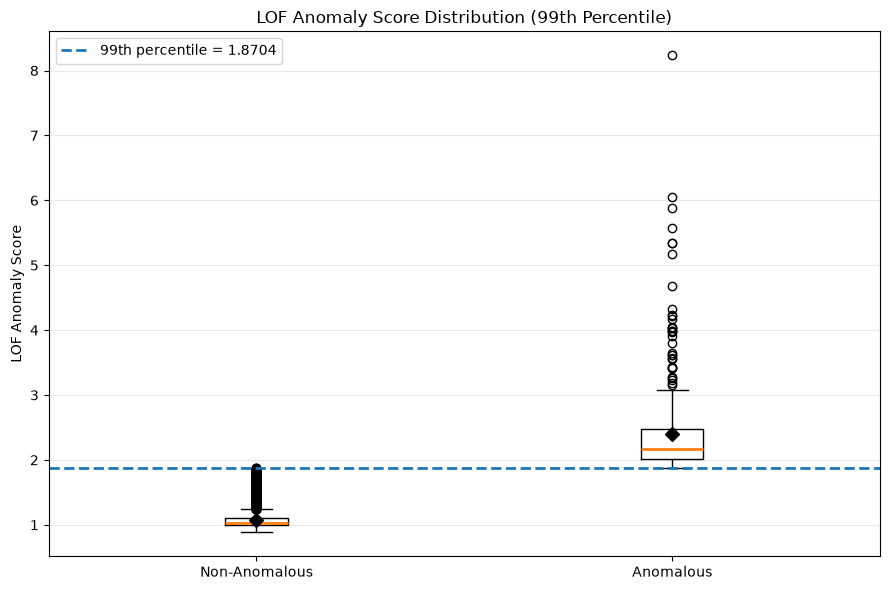

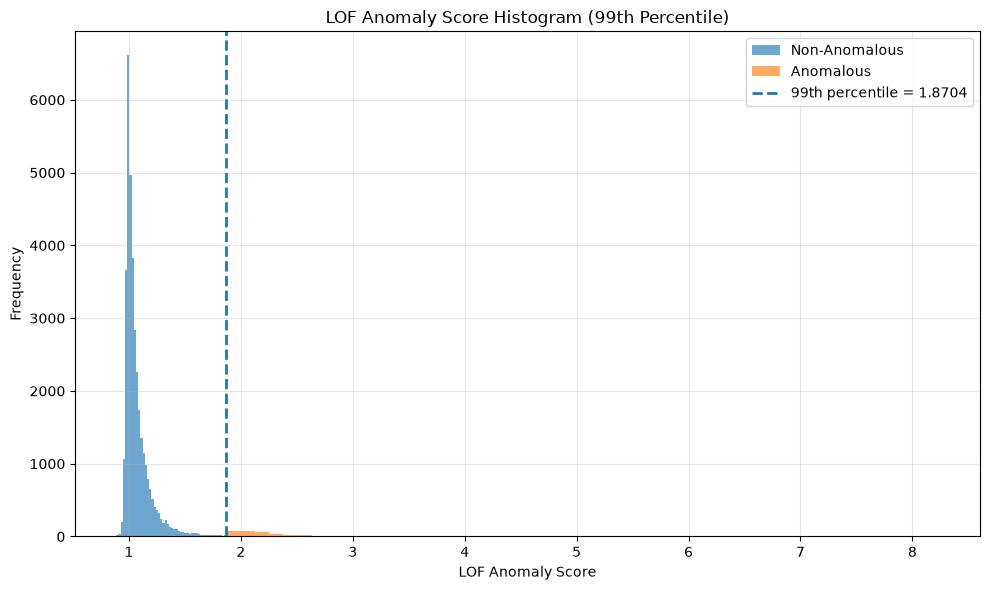


LOF descriptive analysis completed successfully.


In [48]:
AnomalyAnalysis(lof_detection, "LOF", alpha=0.01).present()


**Observations**

Using 20 neighbors and the 1% criterion, LOF flags 350 validation observations (0.97%) above the training-derived threshold of 1.8704. Their mean score is 2.4041, compared with 1.0695 for non-flagged observations, while their median is 2.1662 versus 1.0309. Compared with the 5% anomalous group, these higher scores indicate stronger density contrasts relative to neighboring training observations. The higher threshold selects a more extreme subset without changing the model or individual scores.

The flagged group has higher median product prices, sales, and discounts than both the non-flagged group and the broader 5% anomalous group. Median product price increases from 129.99 at 5% to 260.65 at 1%, while median sales rises from 199.98 to 260.65. Median benefit also increases from 27.90 to 60.43, indicating that losses are not the dominant descriptive pattern. Quantities are concentrated at one item, although the separate feature summaries do not establish a single profile shared by every flagged transaction.

The flagged observations may include both local outliers and globally isolated transactions, since either can exhibit lower density than its reference neighborhood. LOF assigns an anomaly score to each observation, but the selected threshold combines potentially different outlier profiles into a single flagged group. Examining individual neighborhoods and the wider data distribution can help distinguish these profiles and reveal patterns concealed by the aggregate descriptive statistics.

## **7. Isolation Forest**

### **7.1 Notation**

**1. What is Isolation Forest?**

Isolation Forest is an unsupervised anomaly detection algorithm that identifies unusual observations by measuring how easily they can be isolated through random partitions of the dataset.

Unlike distance-based methods such as Mahalanobis Distance or LOF, Isolation Forest uses an **ensemble of randomly generated isolation trees**. Anomalous observations generally require fewer splits to be isolated, resulting in shorter average path lengths.

For an observation $x_i$, the theoretical anomaly score is defined as:

$$
\boxed{s(x_i,n)=2^{-\frac{E[h(x_i)]}{c(n)}}}
$$

Where:

- $x_i$: Feature vector of observation $i$.
- $E[h(x_i)]$: Average path length across the isolation trees.
- $c(n)$: Normalization factor for the expected path length.
- $n$: Number of observations sampled per tree.

A higher anomaly score indicates that an observation is easier to isolate, making it a potential anomaly.

**2. Metric: Isolation Forest Anomaly Score**

For this experiment, we will use the **Isolation Forest Anomaly Score** to identify unusual observations.

Rather than measuring distances or local densities, Isolation Forest evaluates how easily each observation can be separated from the rest of the dataset through random feature selections and splits.

The algorithm operates on all **10 standardized numerical features** of the dataset.

Each isolation tree is constructed using a randomly selected subset of training observations. The final anomaly score is obtained by aggregating the isolation behavior across multiple trees.

In scikit-learn, `score_samples()` assigns lower values to more anomalous observations. Therefore, we reverse its sign:

$$
\boxed{A(x_i)=-\operatorname{score\_samples}(x_i)}
$$

Where:

- $A(x_i)$: Anomaly score for observation $i$.
- `score_samples`: Isolation Forest scoring function from scikit-learn.

With this transformation, **higher scores indicate more anomalous observations**.

**3. Anomaly Detection Thresholds**

As with PCA, ICA, and Mahalanobis Distance, we will use empirical percentiles of the **training anomaly scores** to determine which observations are anomalous.

The threshold for significance level $\alpha$ is:

$$
\boxed{\tau_\alpha=Q_{1-\alpha}(A_{\text{train}})}
$$

An observation is classified as anomalous when:

$$
\boxed{A(x_i)>\tau_\alpha}
$$

We will evaluate two thresholds:

| Significance level | Training percentile | Interpretation |
|---|---|---|
| $\alpha=0.05$ | 95th | Flags observations exceeding the 95th percentile |
| $\alpha=0.01$ | 99th | Flags observations exceeding the 99th percentile |

The 99th-percentile threshold is more restrictive, identifying observations that are particularly easy to isolate.

These are **empirical detection thresholds**, not guarantees of 5% or 1% false-positive rates, because the dataset does not contain verified anomaly labels.

### **7.2 Hyperparameters Search**

In [50]:
if_search = IsolationForestSearch().run(data)


Evaluating Trees_50_Samples_256...
Evaluating Trees_50_Samples_512...
Evaluating Trees_50_Samples_1024...
Evaluating Trees_50_Samples_4096...
Evaluating Trees_50_Samples_1.0...
Evaluating Trees_100_Samples_256...
Evaluating Trees_100_Samples_512...
Evaluating Trees_100_Samples_1024...
Evaluating Trees_100_Samples_4096...
Evaluating Trees_100_Samples_1.0...
Evaluating Trees_200_Samples_256...
Evaluating Trees_200_Samples_512...
Evaluating Trees_200_Samples_1024...
Evaluating Trees_200_Samples_4096...
Evaluating Trees_200_Samples_1.0...
Evaluating Trees_400_Samples_256...
Evaluating Trees_400_Samples_512...
Evaluating Trees_400_Samples_1024...
Evaluating Trees_400_Samples_4096...
Evaluating Trees_400_Samples_1.0...

ISOLATION FOREST HYPERPARAMETER METRICS


,Configuration,N Estimators,Max Samples,Score Mean,Score Median,Score Std,Score P95,Score P99,Score Max,Execution Time (s)
0,Trees_50_Samples_256,50,256.0,0.4678,0.4565,0.0514,0.5713,0.6256,0.7754,0.2014
1,Trees_50_Samples_512,50,512.0,0.4683,0.4565,0.0508,0.5674,0.6220,0.7885,0.2761
2,Trees_50_Samples_1024,50,1024.0,0.4580,0.4459,0.0510,0.5580,0.6244,0.8067,0.3619
3,Trees_50_Samples_4096,50,4096.0,0.4521,0.4409,0.0460,0.5425,0.6044,0.8065,0.6712
4,Trees_50_Samples_1.0,50,1.0,0.4426,0.4325,0.0390,0.5184,0.5767,0.8113,0.7109
5,Trees_100_Samples_256,100,256.0,0.4664,0.4543,0.0515,0.5696,0.6303,0.7691,0.6503
6,Trees_100_Samples_512,100,512.0,0.4617,0.4508,0.0503,0.5615,0.6210,0.7916,0.4712
7,Trees_100_Samples_1024,100,1024.0,0.4528,0.4403,0.0494,0.5508,0.6161,0.8117,0.6258
8,Trees_100_Samples_4096,100,4096.0,0.4505,0.4387,0.0462,0.5426,0.6042,0.7945,0.6321
9,Trees_100_Samples_1.0,100,1.0,0.4401,0.4299,0.0390,0.5156,0.5755,0.8125,0.7794



SENSITIVITY TO NUMBER OF TREES


,Max Samples,Trees 1,Trees 2,Comparison,Spearman,Top 1% Jaccard
0,256.0,50,100,50 vs 100,0.9832,0.7659
1,256.0,100,200,100 vs 200,0.9937,0.8329
2,256.0,200,400,200 vs 400,0.9955,0.9153
3,512.0,50,100,50 vs 100,0.9857,0.6876
4,512.0,100,200,100 vs 200,0.9938,0.8660
5,512.0,200,400,200 vs 400,0.9967,0.9003
6,1024.0,50,100,50 vs 100,0.9860,0.7573
7,1024.0,100,200,100 vs 200,0.9926,0.8708
8,1024.0,200,400,200 vs 400,0.9961,0.9255
9,4096.0,50,100,50 vs 100,0.9863,0.8283



SENSITIVITY TO SAMPLE SIZE


,N Estimators,Samples 1,Samples 2,Comparison,Spearman,Top 1% Jaccard
0,50,256,512.0,256 vs 512,0.9495,0.5947
1,50,512,1024.0,512 vs 1024,0.9503,0.6197
2,50,1024,4096.0,1024 vs 4096,0.9343,0.6721
3,50,4096,1.0,4096 vs 1.0,0.9170,0.6417
4,100,256,512.0,256 vs 512,0.9741,0.7446
5,100,512,1024.0,512 vs 1024,0.9763,0.7702
6,100,1024,4096.0,1024 vs 4096,0.9690,0.7573
7,100,4096,1.0,4096 vs 1.0,0.9408,0.6492
8,200,256,512.0,256 vs 512,0.9845,0.8469
9,200,512,1024.0,512 vs 1024,0.9854,0.7965



Isolation Forest hyperparameter evaluation completed.


### **7.3 Metrics Visualization**

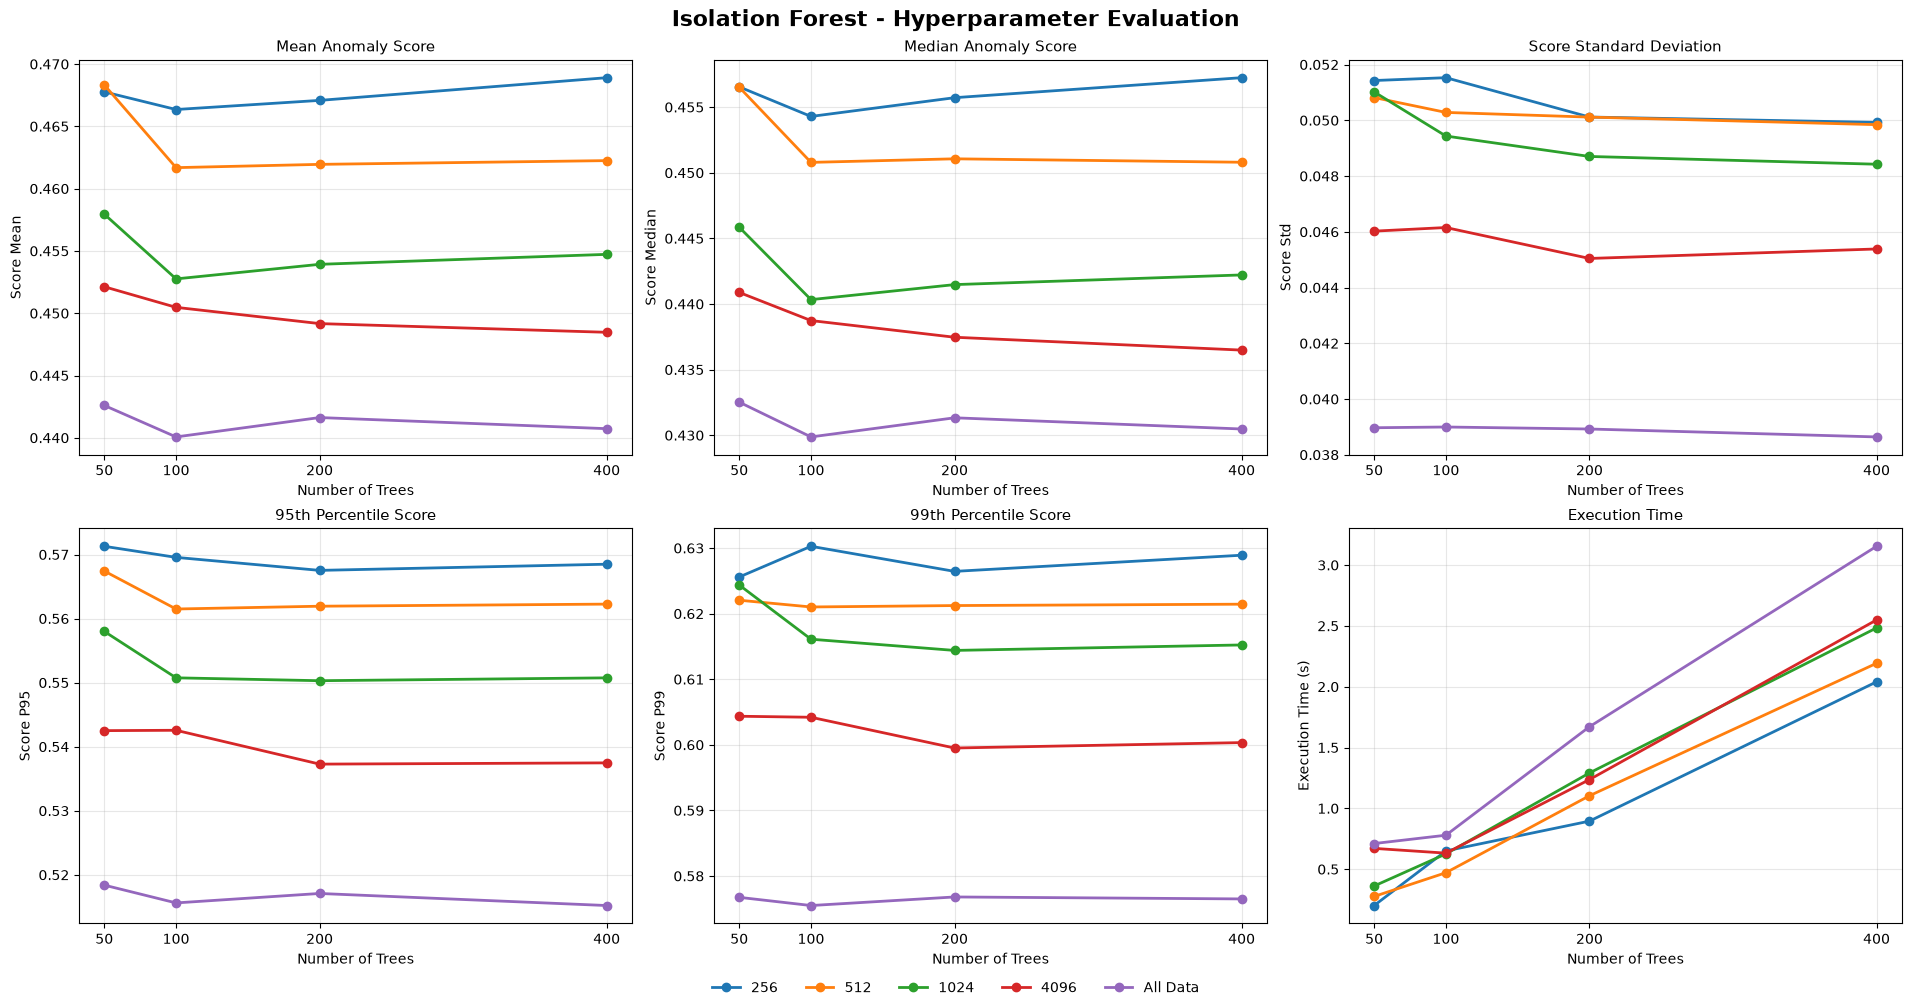

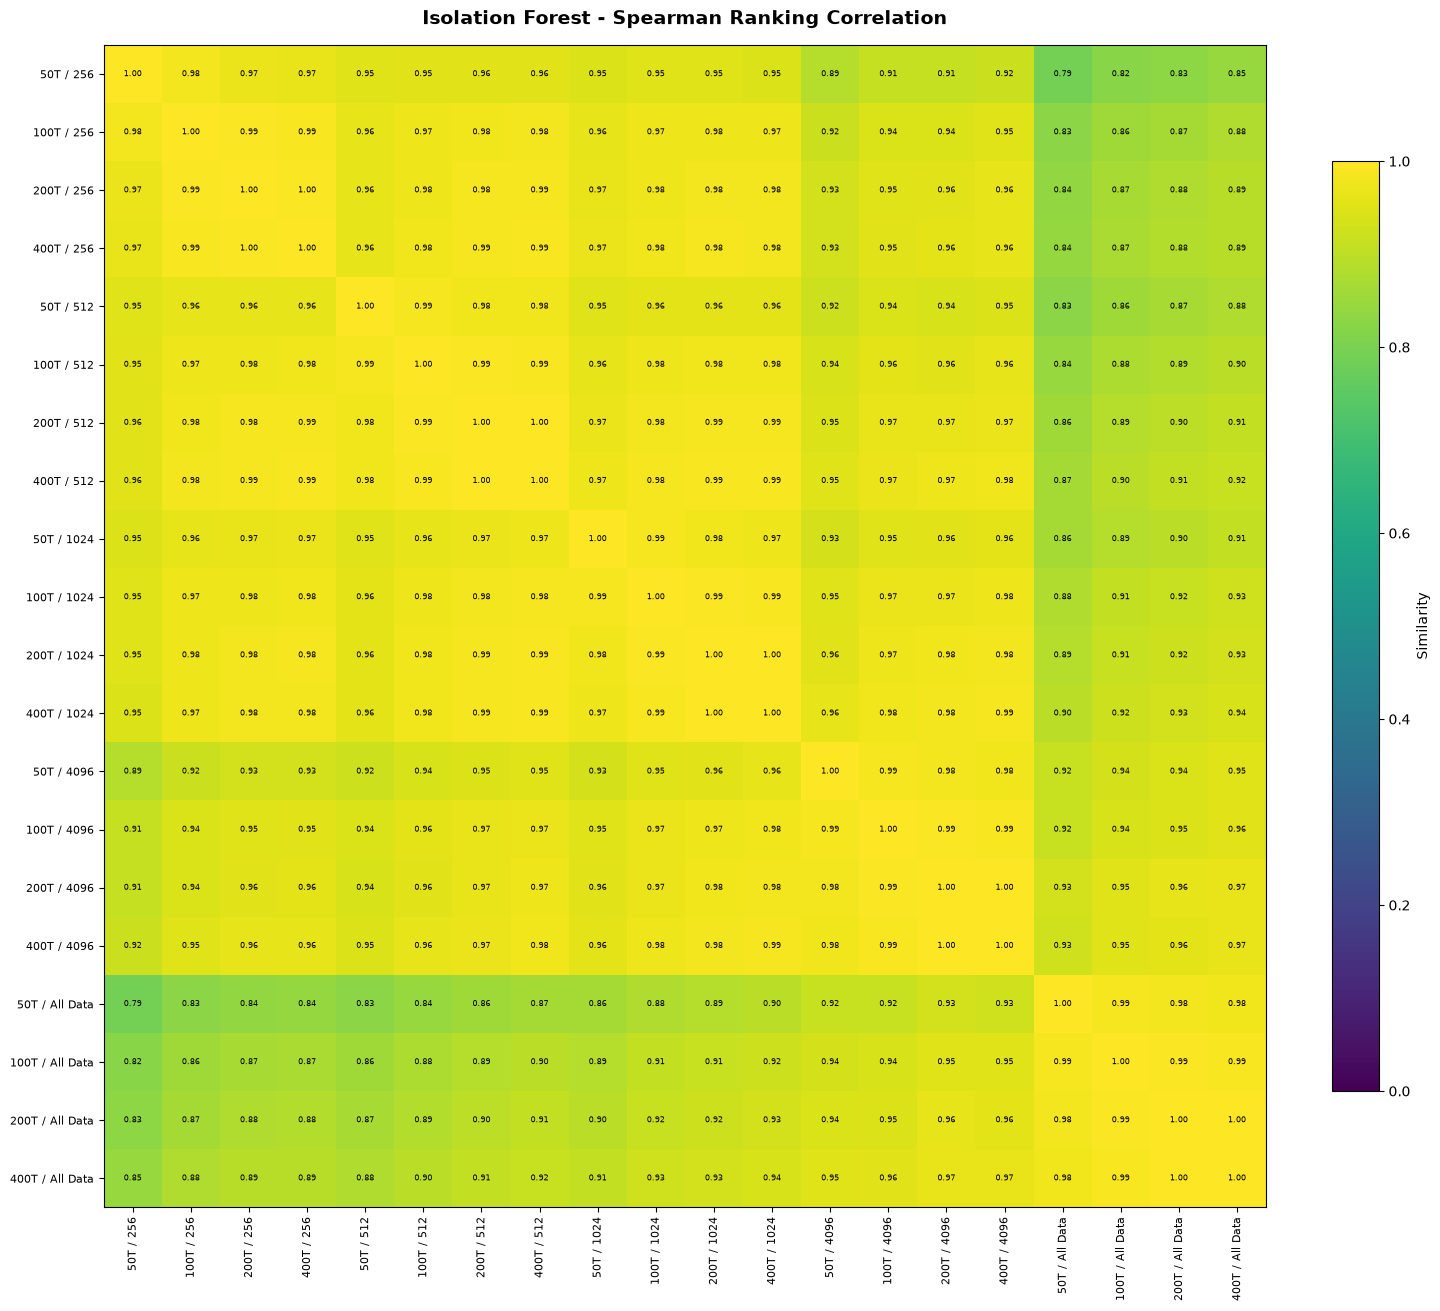

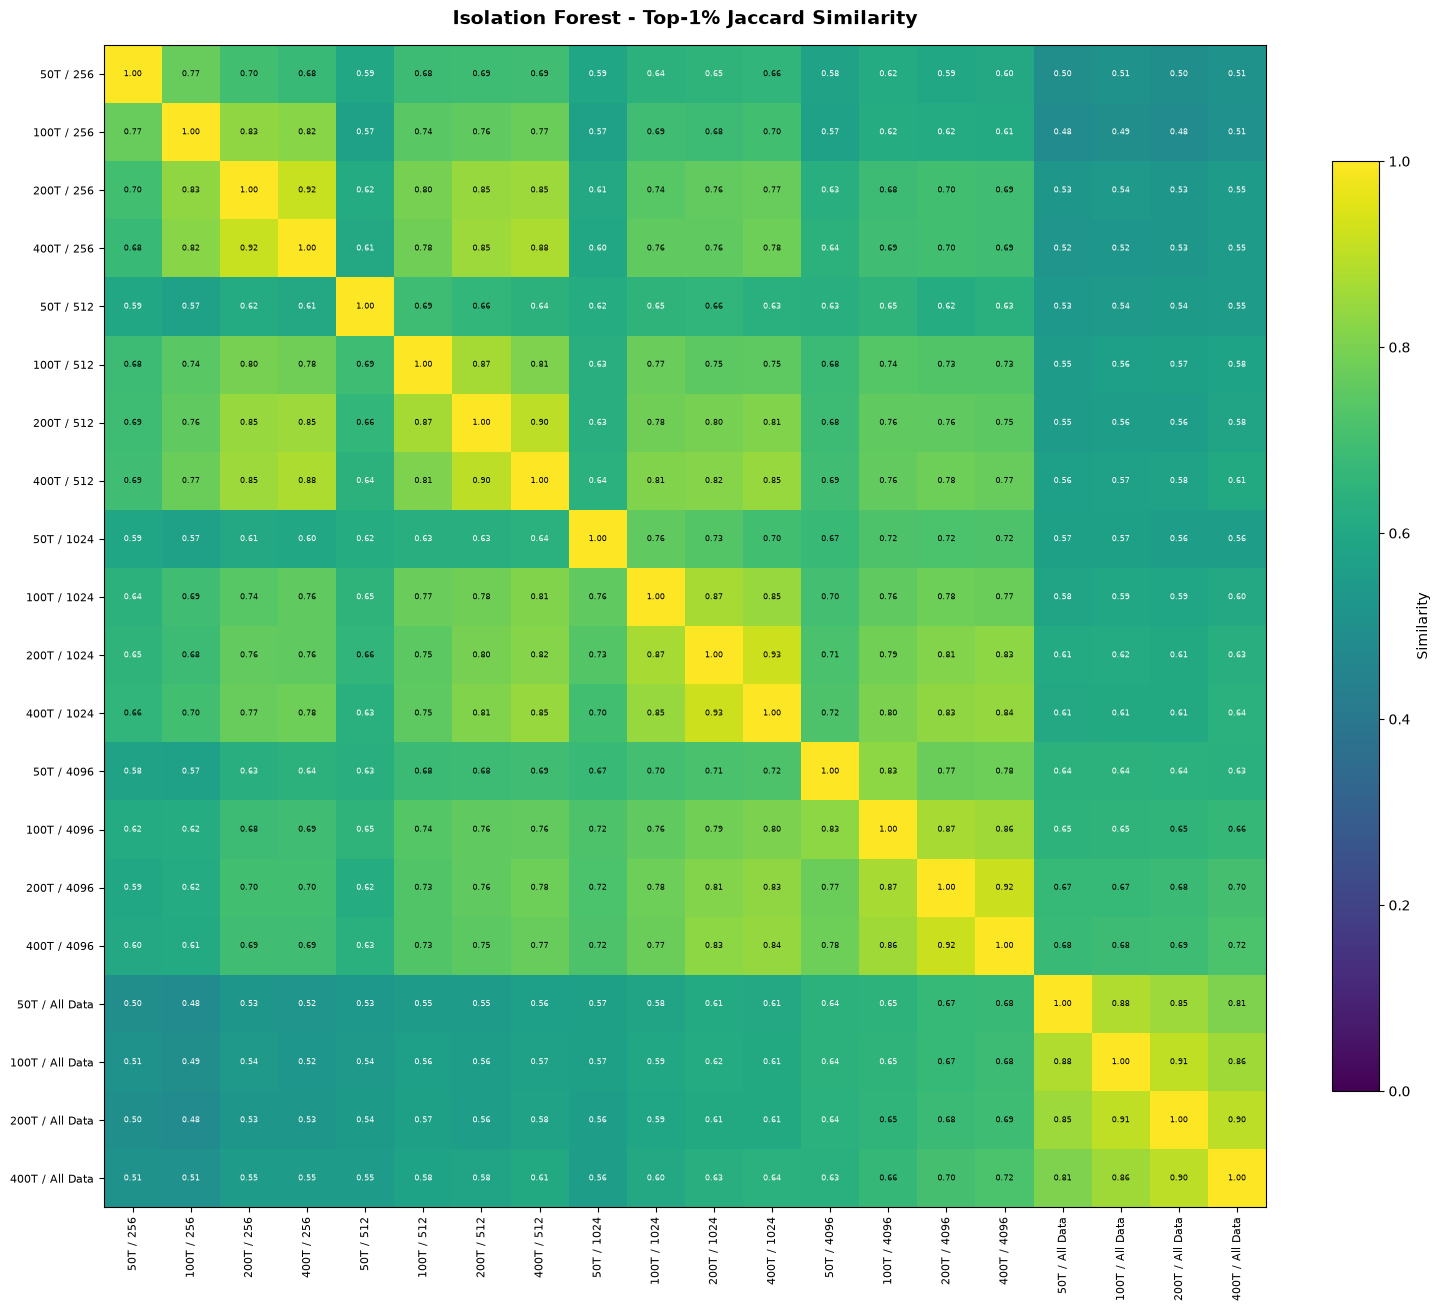

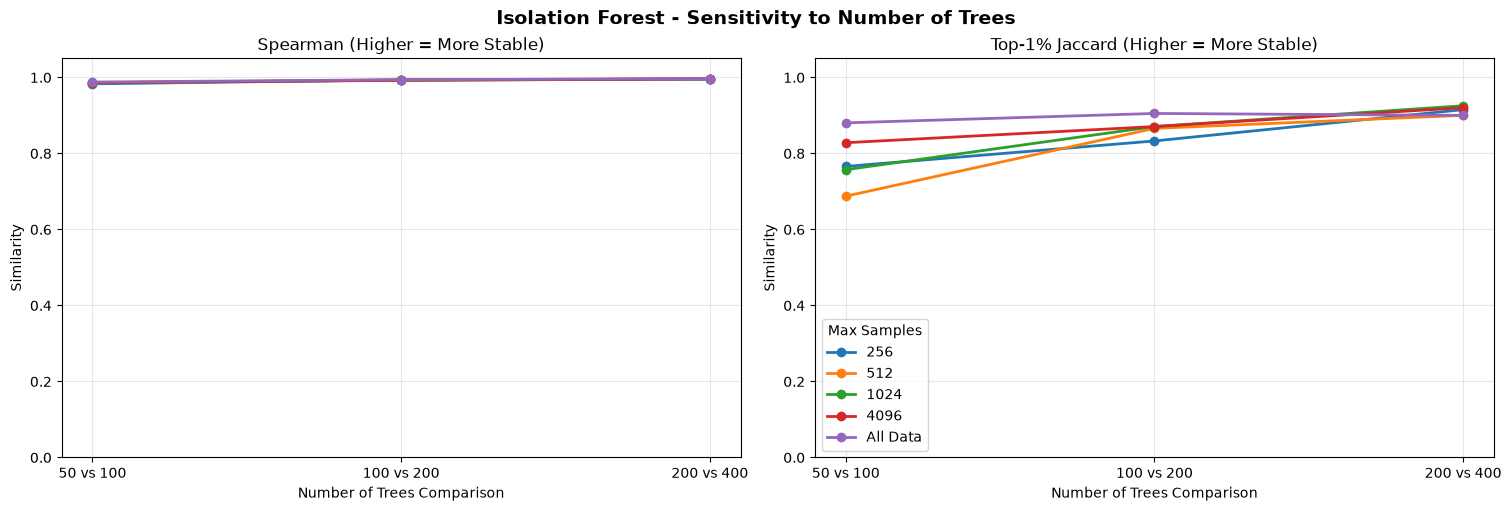

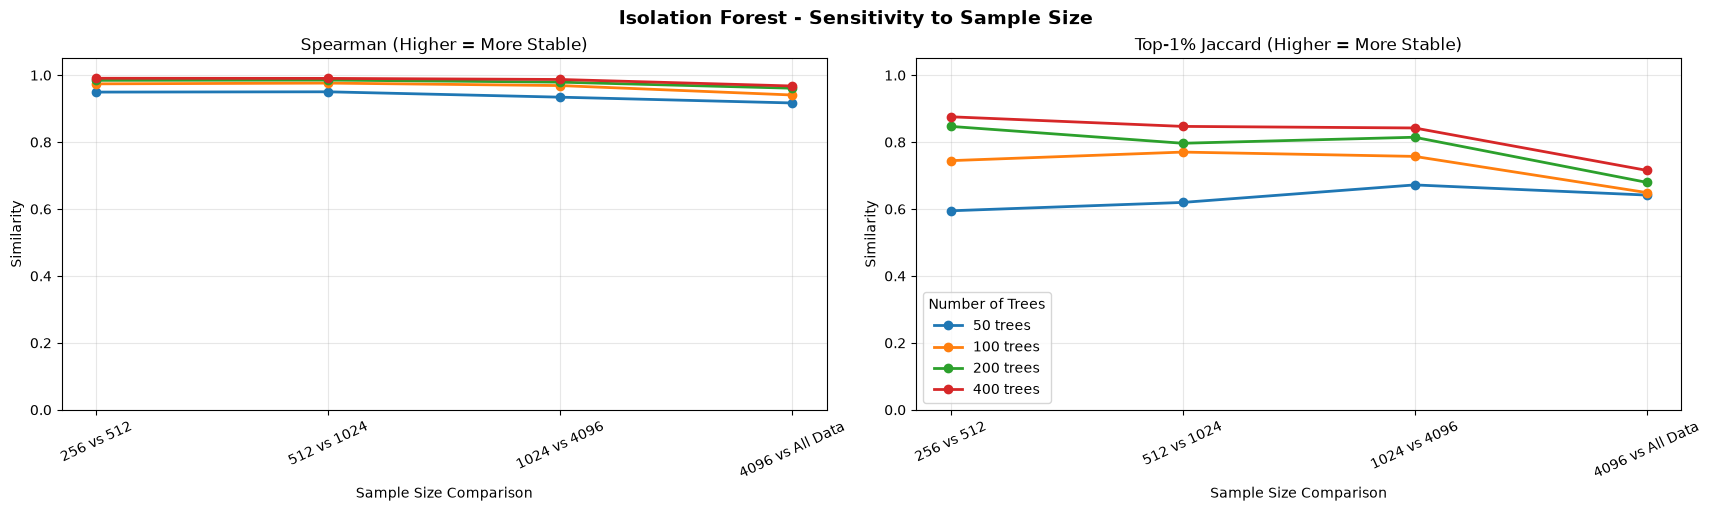


All Isolation Forest visualizations saved successfully.


In [56]:
plot_if_search(if_search)


**Observations**

**400 trees and 1024 samples per tree** are selected for the Isolation Forest model based on the hyperparameter sensitivity analysis. The Spearman ranking correlations were consistently high, indicating that the model maintained similar anomaly rankings across different configurations. In particular, the comparison between 200 and 400 trees using 1024 samples achieved a Spearman correlation close to 1.00 and a Top-1% Jaccard similarity of approximately 0.93, demonstrating strong agreement in both the overall rankings and the identification of extreme anomalies. Although 200 trees already provided substantial stability, we selected **400 trees** to favor a larger ensemble and potentially reduce variability in anomaly scores, despite the additional computational cost. Furthermore, 1024 samples per tree were chosen as an intermediate configuration that maintains substantial agreement without relying on either very small samples or the complete training dataset. These findings suggest that 400 trees and 1024 samples per tree represent a reasonable configuration for obtaining stable anomaly rankings and identifying anomalous observations. However, this selection reflects ranking consistency rather than confirmed anomaly detection accuracy.

### **7.4 Seed Stability Isolation Forest with 400T and max_samples=1024**

In [57]:
if_stability = IsolationForestStability(n_estimators=400, max_samples=1024).run(data)


Training Isolation Forest with seed=0...
Training Isolation Forest with seed=21...
Training Isolation Forest with seed=42...
Training Isolation Forest with seed=123...
Training Isolation Forest with seed=7...
Training Isolation Forest with seed=13...
Training Isolation Forest with seed=57...
Training Isolation Forest with seed=99...
Training Isolation Forest with seed=202...
Training Isolation Forest with seed=314...

ISOLATION FOREST - RANDOM SEED STABILITY
Number of trees: 400
Samples per tree: 1024
Number of seeds: 10
Pairwise comparisons: 45

PAIRWISE STABILITY SUMMARY


,Spearman,Top 1% Jaccard
count,45.0000,45.0000
mean,0.9917,0.8805
std,0.0015,0.0199
min,0.9887,0.8329
25%,0.9906,0.8708
50%,0.9919,0.8854
75%,0.9929,0.8903
max,0.9942,0.9153



PER-SEED SCORE METRICS


,Seed,Score Mean,Score Median,Score Std,Score P95,Score P99,Execution Time (s)
0,0,0.4570,0.4451,0.0471,0.5515,0.6138,2.4535
1,21,0.4567,0.4452,0.0480,0.5518,0.6173,2.4532
2,42,0.4547,0.4422,0.0484,0.5507,0.6152,2.3867
3,123,0.4549,0.4429,0.0484,0.5515,0.6147,2.3523
4,7,0.4570,0.4451,0.0489,0.5550,0.6160,2.4960
5,13,0.4571,0.4449,0.0488,0.5541,0.6128,2.4071
6,57,0.4560,0.4441,0.0480,0.5514,0.6135,2.6308
7,99,0.4556,0.4436,0.0483,0.5516,0.6149,2.7985
8,202,0.4568,0.4445,0.0485,0.5528,0.6137,2.8595
9,314,0.4578,0.4461,0.0480,0.5523,0.6146,2.8110



PER-OBSERVATION SCORE STABILITY


,Mean Score,Score Std,Score CV
count,36104.0000,36104.0000,36104.0000
mean,0.4564,0.0034,0.0073
std,0.0481,0.0012,0.0020
min,0.3886,0.0007,0.0015
25%,0.4222,0.0025,0.0058
50%,0.4445,0.0032,0.0071
75%,0.4768,0.0041,0.0086
max,0.7975,0.0097,0.0160



Isolation Forest seed stability analysis completed.


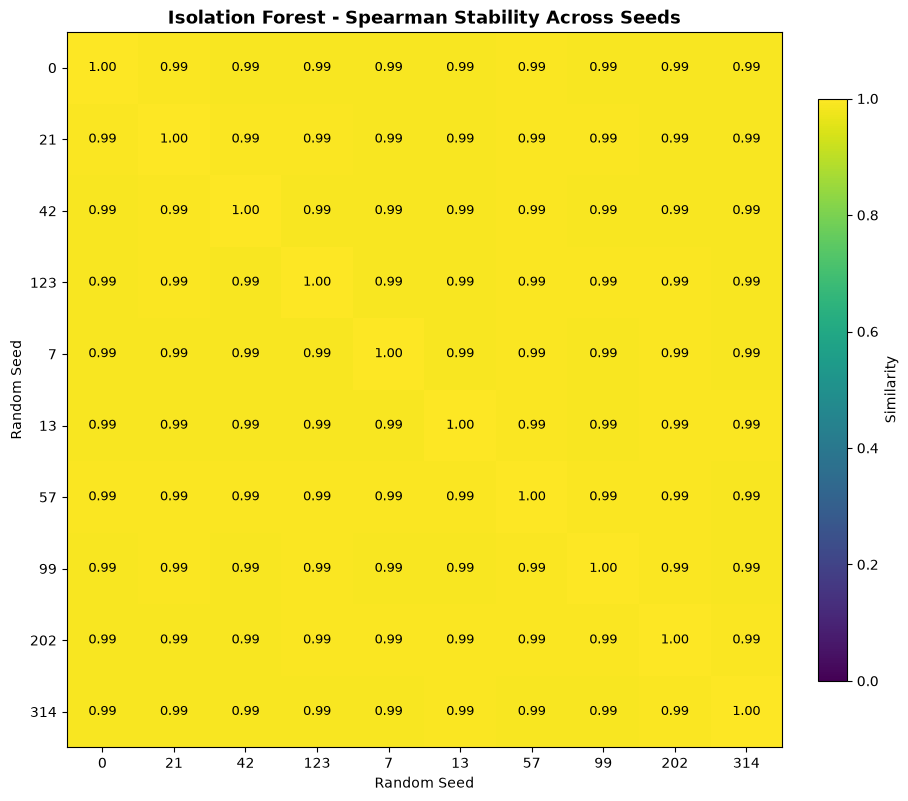

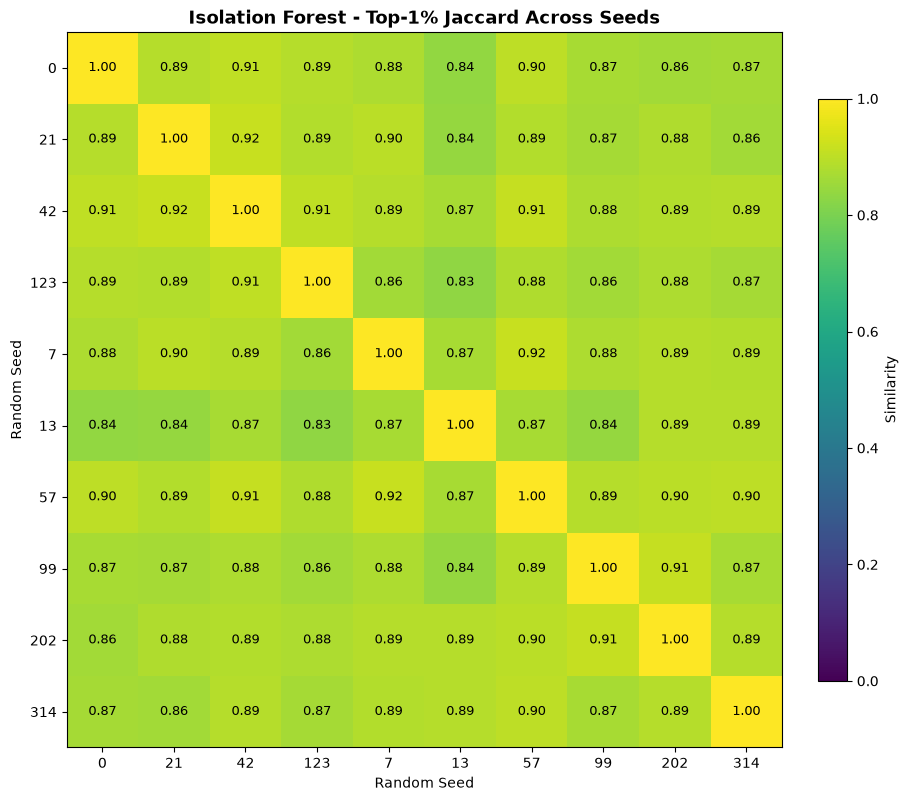


Isolation Forest stability heatmaps saved successfully.


In [58]:
plot_if_stability(if_stability)


**Observations**

The Isolation Forest model with 400 trees and 1024 samples per tree demonstrated strong stability across different random seeds. Spearman ranking correlations remained approximately 0.99, indicating that the model consistently ranked observations in nearly the same order regardless of the random seed used. Additionally, Top-1% Jaccard similarities ranged from approximately 0.83 to 0.92, demonstrating substantial agreement among the observations identified as the most anomalous. These results suggest that the model is highly robust to random initialization, maintaining both consistent overall anomaly rankings and a high degree of overlap among extreme anomalies. Therefore, the selected configuration provides stable and reproducible anomaly detection results across different random seeds, although this consistency does not necessarily guarantee detection accuracy.

### **7.5 Anomaly Detection**

### **7.5.1 Isolation Forest with max_samples=1024 and n_estimators=400**

In [59]:
if_detection = IsolationForestDetector(n_estimators=400, max_samples=1024).fit(data)
if_detection.display()



ISOLATION FOREST - TRAINING THRESHOLDS


,Alpha,Quantile,Threshold
0,0.01,0.99,0.617583
1,0.05,0.95,0.552071



ISOLATION FOREST - DETECTION SUMMARY


,Dataset,Alpha,Threshold,Observations,Anomalies,Anomaly Rate (%),Score Mean,Score Median,Score P95,Score P99,Score Max
0,Train,0.01,0.6176,108311,1084,1.0008,0.4546,0.4420,0.5521,0.6176,0.8013
1,Train,0.05,0.5521,108311,5416,5.0004,0.4546,0.4420,0.5521,0.6176,0.8013
2,Validation,0.01,0.6176,36104,338,0.9362,0.4547,0.4422,0.5507,0.6152,0.8006
3,Validation,0.05,0.5521,36104,1765,4.8887,0.4547,0.4422,0.5507,0.6152,0.8006



FINAL ISOLATION FOREST MODEL
Number of trees: 400
Samples per tree: 1024
Random state: 42
Training observations: 108,311
Validation observations: 36,104
Training time: 1.51 seconds

Empirical thresholds:
Alpha=0.01 (Quantile=0.99): 0.617583
Alpha=0.05 (Quantile=0.95): 0.552071

Isolation Forest training and anomaly detection completed.


### **7.5.2 Anomalies with $\alpha=0.05$**

ISOLATION FOREST | 95TH PERCENTILE | VALIDATION
Number of trees: 400
Samples per tree: 1024
Threshold: 0.552071
Total observations: 36,104
Anomalous: 1,765
Non-anomalous: 34,339
Anomaly rate: 4.89%

ISOLATION FOREST - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1765.0    3.1354    2.0184   
              Days for shipment (scheduled)   1765.0    2.3456    1.6266   
              Benefit per order               1765.0 -133.5081  314.9053   
              Sales per customer              1765.0  367.5906  261.6288   
              Order Item Discount             1765.0   48.7170   49.9699   
              Order Item Discount Rate        1765.0    0.1205    0.0843   
              Order Item Profit Ratio         1765.0   -0.6878    1.0505   
              Order Item Quantity             1765.0    2.8170    1.8440   
              Sales                           1765.0  416.3068  289.0579   
              Product Price                   1765.0  267.0535  329.4705   
Non-Anomalous Days for shipping (real)       34339.0    3.5213    1.6048   
              Days for shipment (scheduled)  34339.0    2.9586    1.3558   
              Benefit per order              34339.0   30.4118   66.6634   
              Sales per customer             34339.0  173.5458   98.3115   
              Order Item Discount            34339.0   19.1527   18.3528   
              Order Item Discount Rate       34339.0    0.1003    0.0696   
              Order Item Profit Ratio        34339.0    0.1631    0.3694   
              Order Item Quantity            34339.0    2.0758    1.4125   
              Sales                          34339.0  192.6983  107.5023   
              Product Price                  34339.0  135.6896  118.9549   

                                                 min     25%     50%     75%  \
Group         Feature                                                          
Anomalous     Days for shipping (real)          0.00    2.00    3.00    5.00   
              Days for shipment (scheduled)     0.00    1.00    2.00    4.00   
              Benefit per order             -2205.00 -339.86  -79.41  114.22   
              Sales per customer                8.66  224.99  335.98  439.96   
              Order Item Discount               0.00   11.70   37.49   74.99   
              Order Item Discount Rate          0.00    0.04    0.12    0.18   
              Order Item Profit Ratio          -2.75   -1.60   -0.32    0.28   
              Order Item Quantity               1.00    1.00    2.00    5.00   
              Sales                            11.29  250.00  399.98  499.95   
              Product Price                     9.99   99.99   99.99  399.98   
Non-Anomalous Days for shipping (real)          0.00    2.00    3.00    5.00   
              Days for shipment (scheduled)     0.00    2.00    4.00    4.00   
              Benefit per order              -431.97    8.61   32.03   64.16   
              Sales per customer                8.29  101.97  159.94  239.96   
              Order Item Discount               0.00    5.20   13.49   27.19   
              Order Item Discount Rate          0.00    0.04    0.09    0.16   
              Order Item Profit Ratio          -2.70    0.08    0.28    0.36   
              Order Item Quantity               1.00    1.00    1.00    3.00   
              Sales                             9.99  119.98  179.97  252.88   
              Product Price                     9.99   50.00   59.99  199.99   

                                                 max  
Group         Feature                                 
Anomalous     Days for shipping (real)          6.00  
              Days for shipment (scheduled)     4.00  
              Benefit per order               720.00  
              Sales per customer             1679.99  
              Order Item Discount             500.00  
              Order Item Discount Rate          0.25  
              Order Item Profit Ratio           0.50  
              Order Item Quantity               5.00  
              Sales                          1999.99  
        


ISOLATION FOREST - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1765.0000,34339.0000
mean,0.5951,0.4475
std,0.0469,0.0359
min,0.5521,0.3862
25%,0.5651,0.4196
50%,0.5804,0.4397
75%,0.6064,0.4689
max,0.8006,0.5521


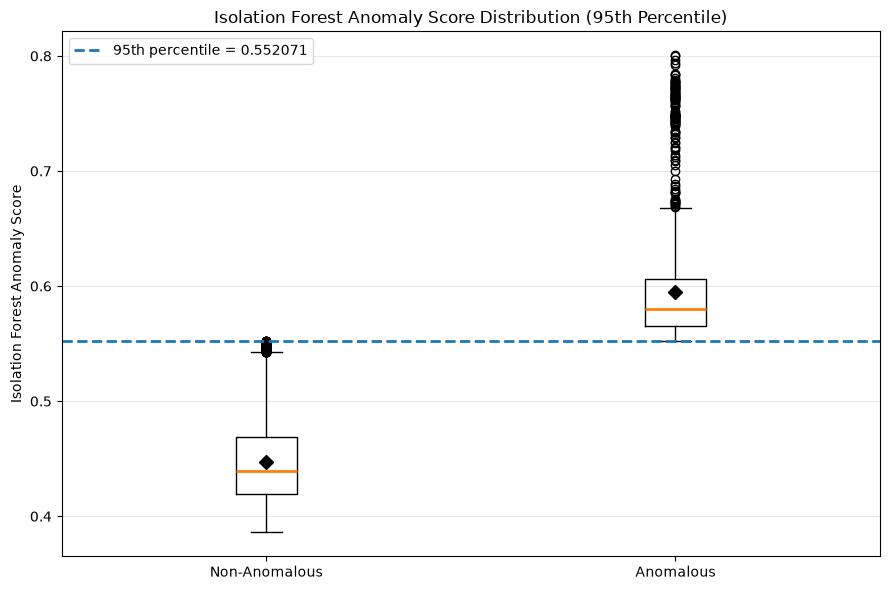

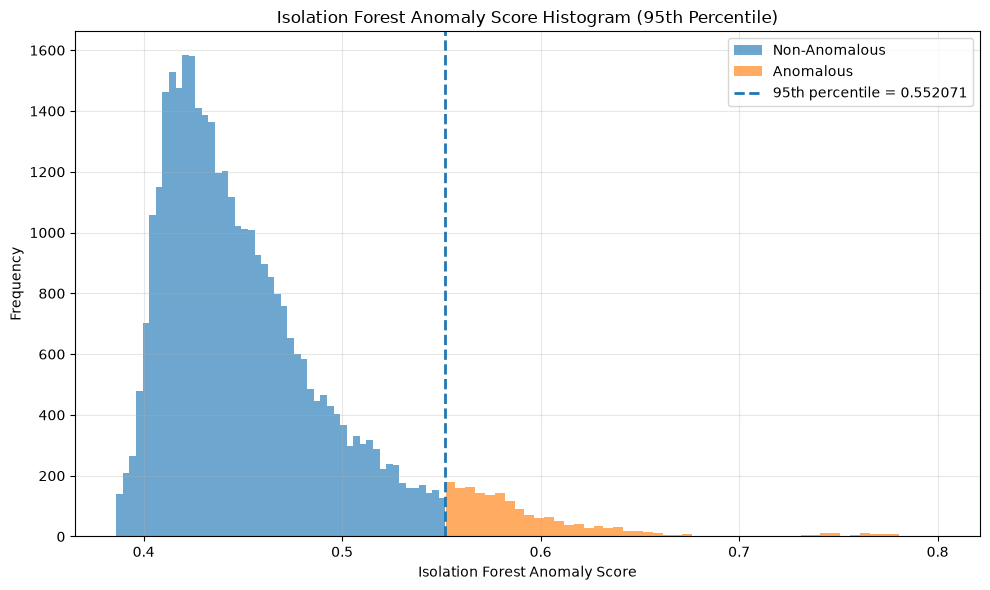


Isolation Forest descriptive analysis completed successfully.


In [60]:
AnomalyAnalysis(if_detection, "IF", alpha=0.05).present()


**Observations**

Using 400 trees and 1,024 observations per tree, Isolation Forest flags 1,765 validation observations (4.89%) under the 5% criterion. Their scores exceed the training-derived threshold of 0.552071. The flagged mean score is 0.5951, compared with 0.4475 for non-flagged observations, while the median is 0.5804 versus 0.4397. Higher scores indicate that transactions are isolated through shorter average paths in the forest, rather than a higher confirmed probability of fraud or error.

The flagged group exhibits higher median sales, customer transaction values, and absolute discounts. Median sales is 399.98 versus 179.97, sales per customer is 335.98 versus 159.94, and absolute discount is 37.49 versus 13.49. Median profitability is lower: benefit per order is −79.41 compared with 32.03, and profit ratio is −0.32 versus 0.28. Actual shipping duration shows little median separation, with both groups at three days.

These statistics describe a heterogeneous set of transactions that the forest isolates more easily than the majority of observations. Although lower profitability and higher monetary values distinguish the group, profitable transactions are also flagged, and the separate feature summaries do not establish a single shared profile. Explaining individual detections requires examining how their feature combinations influence isolation; the descriptive differences alone do not identify the cause of every flag.

### **7.5.3 Anomalies with $\alpha=0.01$**

ISOLATION FOREST | 99TH PERCENTILE | VALIDATION
Number of trees: 400
Samples per tree: 1024
Threshold: 0.617583
Total observations: 36,104
Anomalous: 338
Non-anomalous: 35,766
Anomaly rate: 0.94%

ISOLATION FOREST - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         338.0    3.2426    2.0090   
              Days for shipment (scheduled)    338.0    2.5178    1.6291   
              Benefit per order                338.0 -270.0680  513.9098   
              Sales per customer               338.0  610.7904  454.8283   
              Order Item Discount              338.0   82.2416   83.6150   
              Order Item Discount Rate         338.0    0.1251    0.0850   
              Order Item Profit Ratio          338.0   -1.0001    1.1851   
              Order Item Quantity              338.0    2.2811    1.7854   
              Sales                            338.0  693.0311  502.4159   
              Product Price                    338.0  580.3225  579.2648   
Non-Anomalous Days for shipping (real)       35766.0    3.5049    1.6254   
              Days for shipment (scheduled)  35766.0    2.9325    1.3735   
              Benefit per order              35766.0   25.1622   84.3467   
              Sales per customer             35766.0  178.9896  103.5766   
              Order Item Discount            35766.0   20.0155   19.6326   
              Order Item Discount Rate       35766.0    0.1011    0.0703   
              Order Item Profit Ratio        35766.0    0.1321    0.4407   
              Order Item Quantity            35766.0    2.1105    1.4418   
              Sales                          35766.0  199.0048  113.5791   
              Product Price                  35766.0  137.9703  121.4739   

                                                 min      25%      50%  \
Group         Feature                                                    
Anomalous     Days for shipping (real)          0.00    2.000    3.000   
              Days for shipment (scheduled)     0.00    1.000    4.000   
              Benefit per order             -2205.00 -664.065 -330.440   
              Sales per customer                9.23  319.980  395.980   
              Order Item Discount               0.00   20.000   60.000   
              Order Item Discount Rate          0.00    0.040    0.130   
              Order Item Profit Ratio          -2.75   -2.175   -0.800   
              Order Item Quantity               1.00    1.000    1.000   
              Sales                            11.54  399.960  499.950   
              Product Price                    11.54   99.990  399.980   
Non-Anomalous Days for shipping (real)          0.00    2.000    3.000   
              Days for shipment (scheduled)     0.00    2.000    4.000   
              Benefit per order              -666.37    7.390   31.555   
              Sales per customer                8.29  103.990  163.930   
              Order Item Discount               0.00    5.400   14.000   
              Order Item Discount Rate          0.00    0.040    0.090   
              Order Item Profit Ratio          -2.75    0.080    0.270   
              Order Item Quantity               1.00    1.000    1.000   
              Sales                             9.99  119.980  199.920   
              Product Price                     9.99   50.000   59.990   

                                                   75%      max  
Group         Feature                                            
Anomalous     Days for shipping (real)          5.0000     6.00  
              Days for shipment (scheduled)     4.0000     4.00  
              Benefit per order               136.1275   720.00  
              Sales per customer             1125.0000  1679.99  
              Order Item Discount             106.5200   500.00  
              Order Item Discount Rate          0.2000     0.25  
              Order Item Profit Ratio           0.2500     0.50  
              Order Item Quantity               5.0000     5.00  
              Sales                          1500.0000  1999.99  
              Produ


ISOLATION FOREST - SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,338.0000,35766.0000
mean,0.6716,0.4527
std,0.0550,0.0435
min,0.6177,0.3862
25%,0.6298,0.4204
50%,0.6455,0.4417
75%,0.7234,0.4736
max,0.8006,0.6175


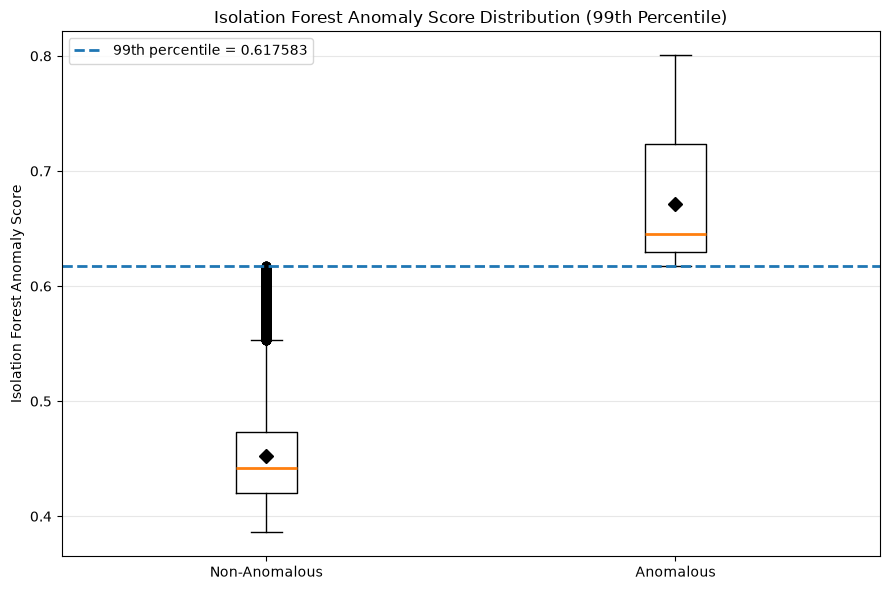

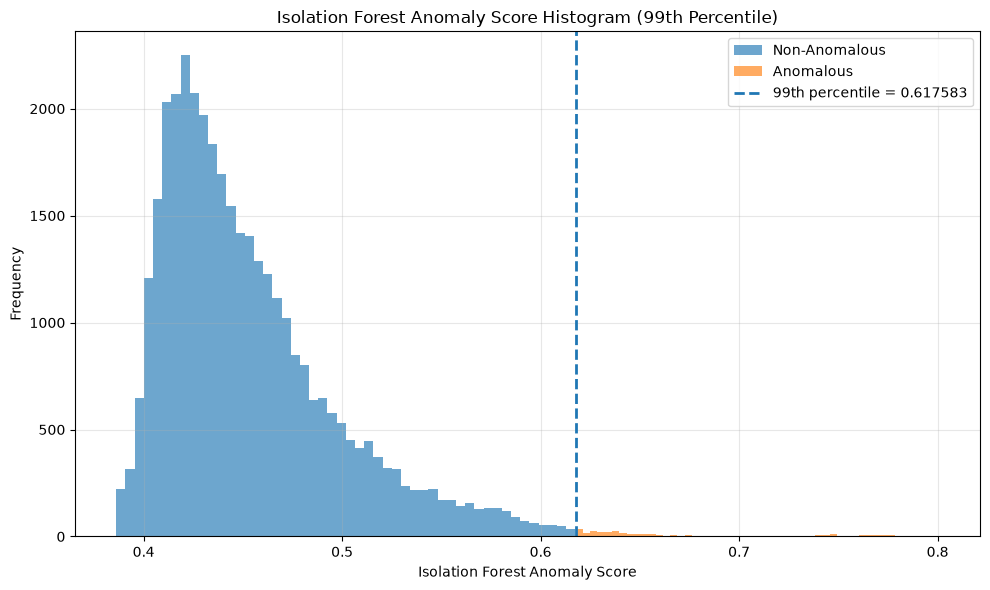


Isolation Forest descriptive analysis completed successfully.


In [61]:
AnomalyAnalysis(if_detection, "IF", alpha=0.01).present()


**Observations**

Using the 1% criterion increases the Isolation Forest threshold from 0.552071 to 0.617583, reducing flagged validation observations from 1,765 (4.89%) to 338 (0.94%). These observations form a subset of those identified at 5%. Their mean score increases from 0.5951 to 0.6716, while their median rises from 0.5804 to 0.6455. Under the notebook’s score convention, these higher values indicate that the forest isolates the selected transactions through shorter average paths.

Compared with the 5% anomalous group, median benefit per order becomes more negative, decreasing from −79.41 to −330.44, while median profit ratio declines from −0.32 to −0.80. Median product price increases from 99.99 to 399.98, and median absolute discount rises from 37.49 to 60.00. However, median quantity decreases from two items to one, and median actual shipping duration remains three days. These changes describe the selected group without establishing a single profile shared by every flagged transaction.

The 1% criterion therefore concentrates on transactions with higher isolation scores, while the 5% criterion includes a broader range of unusual observations. Both loss-making and profitable transactions remain represented, suggesting multiple possible outlier profiles. Individual interpretation requires examining how each transaction’s feature combination affects its isolation; higher scores alone do not establish fraud, data errors, or improved detection accuracy.

## **8. False Negatives, False Positives and Treshold Selection**

Increasing the anomaly-score threshold makes detection more restrictive and can increase false negatives, while decreasing it broadens detection and can increase false positives. However, the dataset has no verified labels distinguishing truly anomalous orders, so these error rates cannot be measured. Although we generated threshold-based flags, we did not train a supervised classification model; instead, we examined how numerical features can support scoring and identifying potential outliers.

PCA, ICA, Mahalanobis distance, and Isolation Forest primarily provide global perspectives, whereas LOF evaluates local density contrasts and can identify both local and global outliers. Differences between their detections are therefore reasonable.

Flagged orders do not necessarily represent business threats or errors: the results include transactions with losses or shipping discrepancies, but also profitable orders. If the business objective is to investigate adverse outcomes, the flagged observations should be further examined using relevant criteria, such as profitability and shipping performance. Profitable orders should not automatically be considered harmless, nor loss-making orders automatically erroneous.

The purpose of this notebook was to demonstrate different scoring methods and threshold-based detection, independently of whether unusual observations have favorable or unfavorable business implications. Consequently, $\alpha=0.05$, corresponding to the training-score 95th percentile, is a defensible exploratory choice because it provides a broader set of unusual cases than $\alpha=0.01$, although it does not establish superior detection accuracy.

Reviewing individual orders and separating them using additional dataset attributes could clarify the context behind their scores, but such detailed investigation lies beyond the scope of this study. The detected outliers also depend on both the selected threshold and each method’s hyperparameters: changing the threshold alters which scores are flagged, while changing hyperparameters can alter the scores, rankings, and resulting detections.